# Prioritising Healthcare Affordability Outreach
### Random forest classification and priority-population profiles · DBA3803 Group 12

## Business objective and proposed solution

### Business problem
Healthcare providers have limited staff and resources to help people with financial assistance and care navigation. Low income and a lack of insurance are useful warning signs, but neither tells the whole story. Insured people may also face costs they cannot afford. For example, the [2023 KFF consumer survey](https://www.kff.org/affordable-care-act/kff-survey-of-consumer-experiences-with-health-insurance/) reported that 58% of insured adults experienced at least one problem using their coverage. **Insurance problems and this project's medical-affordability outcome are different measures**; the KFF finding provides background, rather than a label for our model.

The business decision is therefore **whom to prioritise when the provider cannot contact everyone**. Looking at age, financial circumstances, health and access to care together may find people whom a simple insurance-only rule overlooks.

### Business question
**Given limited outreach capacity, how can a U.S. healthcare provider better identify and prioritise individuals who may require affordability-related support, and what distinct profiles exist among those prioritised for outreach?**

### Objectives
1. Improve outreach allocation compared with random selection and insurance-only targeting **without increasing the number contacted**.
2. Describe distinct profiles within a priority population to inform different financial-assistance and care-navigation conversations.

### Proposed analytical solution
We use a **random forest classifier** to estimate a score for an adult reporting a cost-related unmet medical need. We rank adults from higher to lower scores and select the first **K**, where K is the number the provider can actually contact. This is a classification model used for **prioritisation**, rather than a rule that everyone above 50% must be contacted. We then use a separate, descriptive clustering analysis to understand the priority population.

**No actual contact budget was supplied.** We therefore compare several capacity scenarios and do not declare 10%, 20%, or any other percentage to be the provider's required budget. At a given capacity, every method receives exactly the same number of contacts. A worked example is only an illustration.

### What the prediction means
The outcome is **`YBARCARE`**: needed medical care but did not receive it because of cost during the **previous 12 months**, excluding dental care. Original code 2 (Yes) becomes target 1; original code 1 (No) becomes target 0. Insurance, poverty and health help predict this answer; they do not define a positive case.

The data are cross-sectional survey responses from different people in different years. This is a **proof of concept for identifying reported barriers**, not evidence that the same people will have future barriers or that outreach will improve their outcomes. A high score is a reason to check someone's current needs, not a diagnosis or an assistance-eligibility decision. The 2025 file has been evaluated in earlier project analyses; this run keeps it out of development, but its results are **not a new independent confirmation**.

## How to read and run this notebook
The structure follows the wage example: **inspect → clean → split → visualise → formulate hypotheses → compare models → diagnose → evaluate on a later year**. Classification diagnostics replace wage-regression residual checks. The final business answer and segmentation address the report requirements.

Put this notebook beside `nhis_2023_2024.csv` and `nhis_2025.csv`, restart the Python kernel, and run all cells in order. Required packages: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy`, `kmodes`, and `ipython`. Jupyter is needed to open/run the notebook. If necessary, install them in the notebook's environment with `python -m pip install numpy pandas matplotlib seaborn scikit-learn scipy kmodes ipython jupyter`.

Tuning is deliberately limited so the work remains practical for a student project. The original repository's adult-sample filtering, target recoding, special-code cleaning, survey-weighted summaries and exploratory chart approach are retained and extended. The test file is opened only in Part 8, after **all fitting, settings and profile definitions are fixed**. Running on changed source data can change the numbers.

In [1]:
from pathlib import Path
import sys, json, time, hashlib, platform
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, roc_curve, confusion_matrix,
                             make_scorer, silhouette_score, adjusted_rand_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from kmodes.kprototypes import KPrototypes

RANDOM_STATE = 1
N_JOBS = 4
DATA_DIR = Path('.')
TRAIN_PATH = DATA_DIR / 'nhis_2023_2024.csv'
TEST_PATH = DATA_DIR / 'nhis_2025.csv'
CAPACITIES = (0.05, 0.10, 0.20, 0.30, 0.40, 0.50)
SELECTION_CAPACITIES = (0.05, 0.10, 0.20)
PROFILE_FRACTION = 0.20
TEST_OPENED = False
FIT_LOG = []

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print(f'Python {platform.python_version()} | scikit-learn {sklearn.__version__}')
print('Only the development CSV will be opened initially.')

Python 3.12.14 | scikit-learn 1.8.0
Only the development CSV will be opened initially.


## Part 1: Data Inspection
### Data source, observations and variables
The supplied files are extracts of the **IPUMS National Health Interview Survey (NHIS)**. After filtering, one observation is one sample adult with a valid target answer and positive adult survey weight. We use the supplied year labels to separate development and evaluation. Identifiers distinguish records, rather than explain affordability.

| Role | Variables | Reason |
|---|---|---|
| Target | `YBARCARE` | The reported cost-related unmet medical need we want to identify |
| Predictors | `REGION`, `AGE`, `SEX`, `HISPRACE`, `EDUC`, `EMPSTAT`, `POVERTY`, `HEALTH`, `USUALPL`, `HINOTCOVE` | Information potentially available in an intake or patient record |
| Year | `YEAR` | Determines the time split; excluded from model inputs |
| Identifiers | `SERIAL`, `NHISHID`, `PERNUM`, `NHISPID`, `HHX` | Record checks only; excluded from modelling and clustering |
| Survey design | `SAMPWEIGHT`, `STRATA`, `PSU` | Population-oriented summaries and study design, not individual-need predictors |
| Sample flags | `ASTATFLG`, `CSTATFLG` | Select the appropriate sample; excluded as predictors |

`POVERTY` is a **category of family income relative to the poverty threshold**, not an exact income. `HINOTCOVE = 1` means covered and `= 2` means no coverage. `EMPSTAT = 200` means not employed; this includes people outside the labour force, not only people looking for work. `AGE = 85` is top-coded: it should be read as 85 or older. See the IPUMS references in the appendix.

In [2]:
PREDICTORS = ['REGION', 'AGE', 'SEX', 'HISPRACE', 'EDUC',
              'EMPSTAT', 'POVERTY', 'HEALTH', 'USUALPL', 'HINOTCOVE']
CATEGORICAL = [c for c in PREDICTORS if c != 'AGE']
ID_COLUMNS = ['SERIAL', 'NHISHID', 'PERNUM', 'NHISPID', 'HHX']
DESIGN_COLUMNS = ['SAMPWEIGHT', 'STRATA', 'PSU']
EXCLUDED = ['YBARCARE', 'target', 'YEAR', 'ASTATFLG', 'CSTATFLG'] + ID_COLUMNS + DESIGN_COLUMNS
REQUIRED = set(PREDICTORS + ['YEAR', 'ASTATFLG', 'YBARCARE', 'SAMPWEIGHT', 'NHISPID'])

def verify_structure(data, expected_years, name):
    missing = REQUIRED.difference(data.columns)
    if missing:
        raise ValueError(f'{name} missing columns: {sorted(missing)}')
    years = set(data['YEAR'].dropna().astype(int))
    if years != set(expected_years):
        raise ValueError(f'{name}: years {years}, expected {expected_years}')

if not TRAIN_PATH.exists():
    raise FileNotFoundError('Place the notebook beside nhis_2023_2024.csv.')
development_raw = pd.read_csv(TRAIN_PATH, dtype={'NHISPID': str})
verify_structure(development_raw, {2023, 2024}, 'Development file')
print('Development file shape:', development_raw.shape)
display(development_raw[['YEAR'] + PREDICTORS + ['YBARCARE']].head())
display(pd.DataFrame({'dtype': development_raw.dtypes.astype(str),
                      'raw_missing': development_raw.isna().sum()}))
display(development_raw[['AGE', 'SAMPWEIGHT']].describe().T)
print('Repeated raw person identifiers:', development_raw['NHISPID'].duplicated().sum())

Development file shape: (78203, 22)
Repeated raw person identifiers: 0


,YEAR,REGION,AGE,SEX,HISPRACE,EDUC,EMPSTAT,POVERTY,HEALTH,USUALPL,HINOTCOVE,YBARCARE
0,2023,4,39,1,2,301,100,35,2,1,1,1
1,2023,4,15,2,2,0,0,35,1,2,1,1
2,2023,3,71,2,2,202,200,12,5,2,1,1
3,2023,1,36,1,2,201,100,34,4,2,1,1
4,2023,4,57,2,2,201,100,34,3,2,1,1


,dtype,raw_missing
YEAR,int64,0
SERIAL,int64,0
STRATA,int64,0
PSU,int64,0
NHISHID,object,0
REGION,int64,0
PERNUM,int64,0
NHISPID,object,0
HHX,object,0
SAMPWEIGHT,int64,0


,count,mean,std,min,25%,50%,75%,max
AGE,"78,203.0000",45.5979,44.2325,0.0000,24.0000,45.0000,65.0000,999.0000
SAMPWEIGHT,"78,203.0000","8,467.7091","5,679.5261",265.0000,"4,362.0000","7,086.0000","10,858.0000","39,925.0000"


## Part 2: Clean Data
### Cleaning preserves the meaning of the survey answers
The following rules are fixed from the IPUMS variable definitions, rather than estimated from evaluation data:

1. Keep sample adults (`ASTATFLG == 1`) and valid Yes/No target answers. An unknown answer cannot tell us the correct class, so it is excluded.
2. Convert Yes to target 1 and No to target 0. No other variable changes this label.
3. Replace documented non-response codes with missing values. For example, an unknown age coded 999 is not a 999-year-old adult.
4. Keep records with a positive survey weight to maintain the original sample definition and weighted descriptive analysis.
5. Retain missing predictors. Later, the model pipeline learns the median age from its training rows and uses a fixed missing-category label for other inputs.

We do **not** drop people just because their ten characteristics match another person's: they may be different adults with the same answers. We check person identifiers separately. These are survey-specific eligibility rules for model evaluation; a provider would need its own patient-intake checks.

In [3]:
INVALID_CODES = {
    'REGION': [8, 9], 'AGE': [997, 998, 999], 'SEX': [7, 8, 9],
    'HISPRACE': [97, 98, 99], 'EDUC': [0, 996, 997, 998, 999],
    'EMPSTAT': [0, 900, 997, 998, 999], 'POVERTY': [0, 98, 99],
    'HEALTH': [7, 8, 9], 'USUALPL': [0, 7, 8, 9], 'HINOTCOVE': [0, 7, 8, 9]
}

def prepare_nhis(raw):
    data = raw.loc[raw['ASTATFLG'].eq(1) & raw['YBARCARE'].isin([1, 2])].copy()
    data['target'] = data['YBARCARE'].map({1: 0, 2: 1}).astype('int8')
    for column, codes in INVALID_CODES.items():
        data[column] = pd.to_numeric(data[column], errors='coerce')
        data[column] = data[column].mask(data[column].isin(codes))
    data['SAMPWEIGHT'] = pd.to_numeric(data['SAMPWEIGHT'], errors='coerce')
    return data.loc[data['SAMPWEIGHT'].gt(0)].reset_index(drop=True)

def cleaning_summary(raw, cleaned):
    adult = raw['ASTATFLG'].eq(1)
    return pd.DataFrame({'stage': ['Raw records', 'Sample adults', 'Valid adult target',
                                   'Retained after positive-weight check'],
                         'rows': [len(raw), int(adult.sum()),
                                  int((adult & raw['YBARCARE'].isin([1, 2])).sum()), len(cleaned)]})

development = prepare_nhis(development_raw)
assert development['target'].isin([0, 1]).all()
assert development['AGE'].dropna().between(18, 85).all()
assert development['NHISPID'].notna().all() and development['NHISPID'].is_unique
assert not set(PREDICTORS).intersection(EXCLUDED)
display(cleaning_summary(development_raw, development))
missing_table = pd.DataFrame({'missing_n': development[PREDICTORS].isna().sum(),
                              'missing_%': development[PREDICTORS].isna().mean() * 100})
display(missing_table.sort_values('missing_%', ascending=False))
display(development[PREDICTORS].nunique().rename('distinct_observed_values').to_frame())

,stage,rows
0,Raw records,78203
1,Sample adults,62151
2,Valid adult target,61630
3,Retained after positive-weight check,61630


,missing_n,missing_%
EMPSTAT,1982,3.2160
EDUC,281,0.4559
HINOTCOVE,161,0.2612
AGE,109,0.1769
USUALPL,46,0.0746
HEALTH,34,0.0552
SEX,11,0.0178
REGION,0,0.0000
HISPRACE,0,0.0000
POVERTY,0,0.0000


,distinct_observed_values
REGION,4
AGE,68
SEX,2
HISPRACE,7
EDUC,10
EMPSTAT,2
POVERTY,14
HEALTH,5
USUALPL,3
HINOTCOVE,2


## Part 3: Train / Validation / Test Split
### Why we use three different roles
A provider would apply a model to a later group of people. Keeping years in order gives a more relevant check than randomly mixing all three years.

| Sample | Role | Permitted use |
|---|---|---|
| 2023 | Initial training and five-fold cross-validation | Learn preprocessing and tune model settings using training folds only |
| 2024 | Later-year validation | Compare tuned models and forest finalists; diagnose weaknesses; define descriptive profiles |
| 2023–2024 | Final refit | Relearn the chosen model and baseline parameters using both development years |
| 2025 | Out-of-time evaluation | Apply the frozen procedure and report results; never fit, select, or alter settings |

**Cross-validation (CV)** divides 2023 into five parts. Each time, four teach the model and the fifth checks it. Every record is checked once. We preserve the approximate proportion of positive cases in each part, because relatively few adults reported barriers. The pipeline relearns missing-value replacements and category columns inside each training fold.

The original 2023–2024 exploratory charts are retained because both years are development data. However, 2024 is consequently a **selection sample**, not a new independent test. Survey clustering can also make records less independent than an ordinary random sample; our CV scores are practical tuning checks, not design-adjusted national inference.

In [4]:
initial_train = development.loc[development['YEAR'].eq(2023)].reset_index(drop=True)
validation = development.loc[development['YEAR'].eq(2024)].reset_index(drop=True)
X_train, y_train = initial_train[PREDICTORS], initial_train['target']
X_validation, y_validation = validation[PREDICTORS], validation['target']
assert set(initial_train['YEAR']) == {2023} and set(validation['YEAR']) == {2024}
assert set(initial_train['NHISPID']).isdisjoint(validation['NHISPID'])

def fit_development(estimator, X, y, records, name):
    assert not TEST_OPENED, 'Fitting is locked after the evaluation file is opened.'
    assert set(records['YEAR']).issubset({2023, 2024})
    assert len(X) == len(y) == len(records)
    assert list(X.columns) == PREDICTORS
    FIT_LOG.append({'step': name, 'years': sorted(records['YEAR'].unique().tolist()), 'rows': len(X)})
    return estimator.fit(X, y)

display(development.groupby('YEAR').agg(adults=('target', 'size'),
                                       cases=('target', 'sum'), prevalence=('target', 'mean')))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for train_idx, held_idx in cv.split(X_train, y_train):
    assert set(train_idx).isdisjoint(held_idx)
print('Five 2023-only folds are defined. No 2025 data have been loaded.')

Five 2023-only folds are defined. No 2025 data have been loaded.


,adults,cases,prevalence
YEAR,,,
2023,29276,1716,0.0586
2024,32354,2195,0.0678


## Part 4: Visualize the Data
### Which patterns would make business sense to test?
Unweighted counts describe the supplied respondent sample. **Survey-weighted rates** use `SAMPWEIGHT` to better describe the represented adult population. For pooled rates, dividing each year's weights by two would cancel in the numerator and denominator, so we retain the original rate calculation. We do not interpret pooled weights as a two-year population total.

The charts below use **2023–2024 only**. They show associations and possible modelling ideas. For example, a higher group rate does not prove that being in that group caused a barrier. Differences may also reflect other characteristics.

,year,adults,cases,sample_rate,weighted_rate
0,2023,29276,1716,0.0586,0.0633
1,2024,32354,2195,0.0678,0.0739


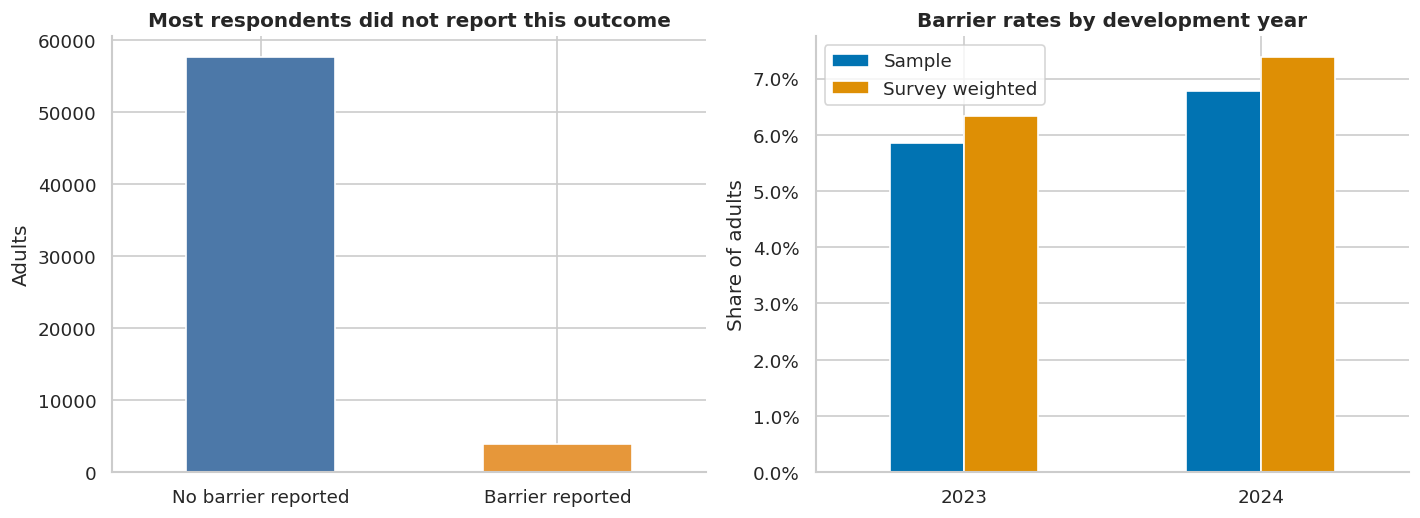

**Interpretation.** The development sample contains **61,630 adults**, including **3,911 reported cases (6.35%)**. A model that says No for everyone would appear accurate while finding no cases. Our evaluation must therefore measure case finding within the contact list.

In [5]:
LABELS = {
 'REGION': {1: 'Northeast', 2: 'Midwest', 3: 'South', 4: 'West'},
 'SEX': {1: 'Male', 2: 'Female'},
 'HISPRACE': {1: 'Hispanic', 2: 'Non-Hispanic White', 3: 'Non-Hispanic Black',
              4: 'Non-Hispanic Asian', 5: 'Non-Hispanic AI/AN',
              6: 'Non-Hispanic AI/AN + other', 7: 'Non-Hispanic other/multiple'},
 'EMPSTAT': {100: 'Employed', 200: 'Not employed'},
 'HEALTH': {1: 'Excellent', 2: 'Very good', 3: 'Good', 4: 'Fair', 5: 'Poor'},
 'USUALPL': {1: 'No usual place', 2: 'Has usual place', 3: 'More than one place'},
 'HINOTCOVE': {1: 'Covered', 2: 'Not covered'},
 'POVERTY': {11: '<0.50', 12: '0.50–0.74', 13: '0.75–0.99', 21: '1.00–1.24',
             22: '1.25–1.49', 23: '1.50–1.74', 24: '1.75–1.99', 31: '2.00–2.49',
             32: '2.50–2.99', 33: '3.00–3.49', 34: '3.50–3.99', 35: '4.00–4.49',
             36: '4.50–4.99', 37: '5.00+'},
 'EDUC': {103: 'Grades 1–11', 116: 'Grade 12, no diploma', 201: 'High-school diploma',
          202: 'GED', 301: 'Some college', 302: 'Associate, vocational',
          303: 'Associate, academic', 400: "Bachelor's", 510: "Master's",
          520: 'Professional / doctorate'}
}

def category_label(value, column):
    if pd.isna(value):
        return 'Missing'
    return LABELS.get(column, {}).get(int(value), f'Code {int(value)}')

def weighted_binary_rate(data):
    return float(np.average(data['target'], weights=data['SAMPWEIGHT']))

def weighted_rate_by(data, column):
    # Retain missing answers as a visible group rather than silently deleting them.
    d = data[[column, 'target', 'SAMPWEIGHT']].copy()
    d['weighted_positive'] = d['target'] * d['SAMPWEIGHT']
    table = d.groupby(column, dropna=False, observed=True).agg(
        n=('target', 'size'), positive_cases=('target', 'sum'),
        unweighted_rate=('target', 'mean'), total_weight=('SAMPWEIGHT', 'sum'),
        weighted_positive=('weighted_positive', 'sum')).reset_index()
    table['weighted_rate'] = table['weighted_positive'] / table['total_weight']
    table['label'] = table[column].map(lambda x: category_label(x, column))
    return table

prevalence = pd.DataFrame([{'year': str(year), 'adults': len(g), 'cases': int(g['target'].sum()),
                           'sample_rate': g['target'].mean(),
                           'weighted_rate': weighted_binary_rate(g)}
                          for year, g in development.groupby('YEAR')])
display(prevalence)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
development['target'].value_counts().sort_index().plot.bar(
    ax=axes[0], color=['#4C78A8', '#E6973A'], rot=0)
axes[0].set(xticklabels=['No barrier reported', 'Barrier reported'], ylabel='Adults',
            xlabel='', title='Most respondents did not report this outcome')
prevalence.set_index('year')[['sample_rate', 'weighted_rate']].plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Barrier rates by development year', ylabel='Share of adults', xlabel='')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(['Sample', 'Survey weighted'])
plt.tight_layout(); plt.show()
display(Markdown(f"**Interpretation.** The development sample contains **{len(development):,} adults**, "
                 f"including **{development['target'].sum():,} reported cases ({development['target'].mean():.2%})**. "
                 'A model that says No for everyone would appear accurate while finding no cases. '
                 'Our evaluation must therefore measure case finding within the contact list.'))

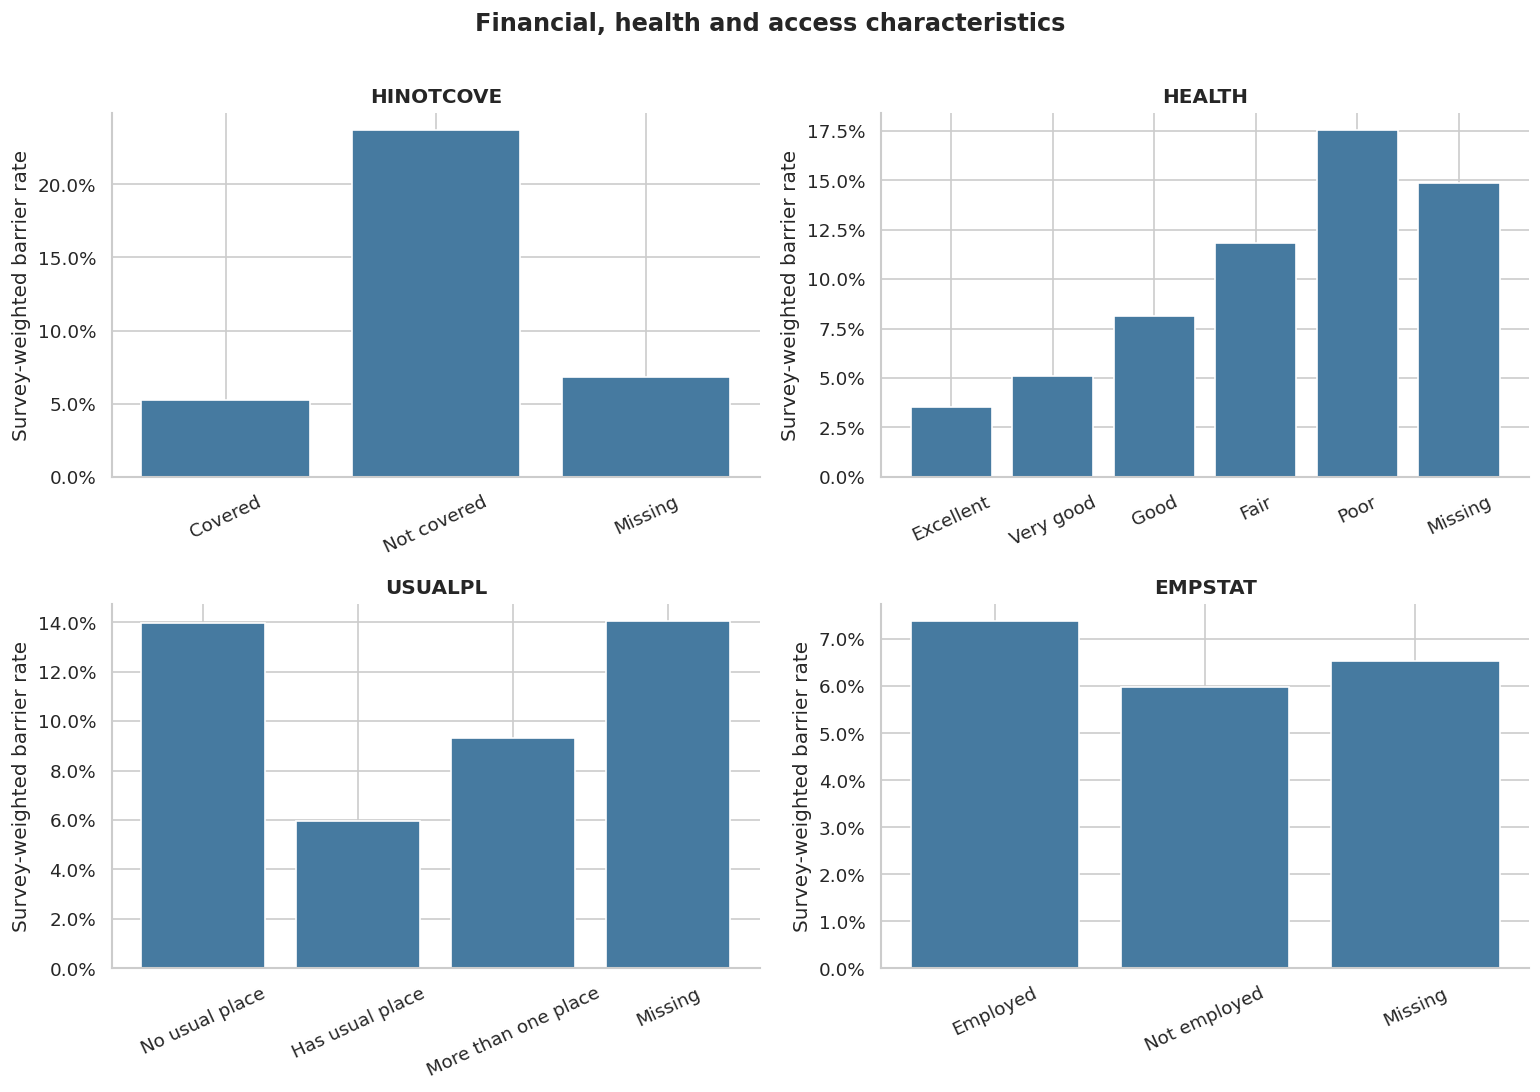

,label,n,positive_cases,weighted_rate
0,Covered,57166,2878,0.0523
1,Not covered,4303,1023,0.2371
2,Missing,161,10,0.0680


**Business interpretation.** The weighted barrier rate is **23.7% without coverage** and **5.2% with coverage**. Insurance is therefore a sensible baseline, but covered adults still report barriers. The full model tests whether other information helps distinguish people within each coverage group. Health and usual-care patterns are reasons to test combined information, rather than causal explanations.

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, column in zip(axes.flat, ['HINOTCOVE', 'HEALTH', 'USUALPL', 'EMPSTAT']):
    rates = weighted_rate_by(development, column)
    ax.bar(rates['label'], rates['weighted_rate'], color='#467AA0')
    ax.set(title=column, ylabel='Survey-weighted barrier rate')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis='x', rotation=25)
plt.suptitle('Financial, health and access characteristics', y=1.01, weight='bold')
plt.tight_layout(); plt.show()
insurance_rates = weighted_rate_by(development, 'HINOTCOVE')
display(insurance_rates[['label', 'n', 'positive_cases', 'weighted_rate']])
covered_rate = insurance_rates.loc[insurance_rates['HINOTCOVE'].eq(1), 'weighted_rate'].iloc[0]
uncovered_rate = insurance_rates.loc[insurance_rates['HINOTCOVE'].eq(2), 'weighted_rate'].iloc[0]
display(Markdown(f'**Business interpretation.** The weighted barrier rate is **{uncovered_rate:.1%} without coverage** '
                 f'and **{covered_rate:.1%} with coverage**. Insurance is therefore a sensible baseline, '
                 'but covered adults still report barriers. The full model tests whether other information '
                 'helps distinguish people within each coverage group. Health and usual-care patterns '
                 'are reasons to test combined information, rather than causal explanations.'))

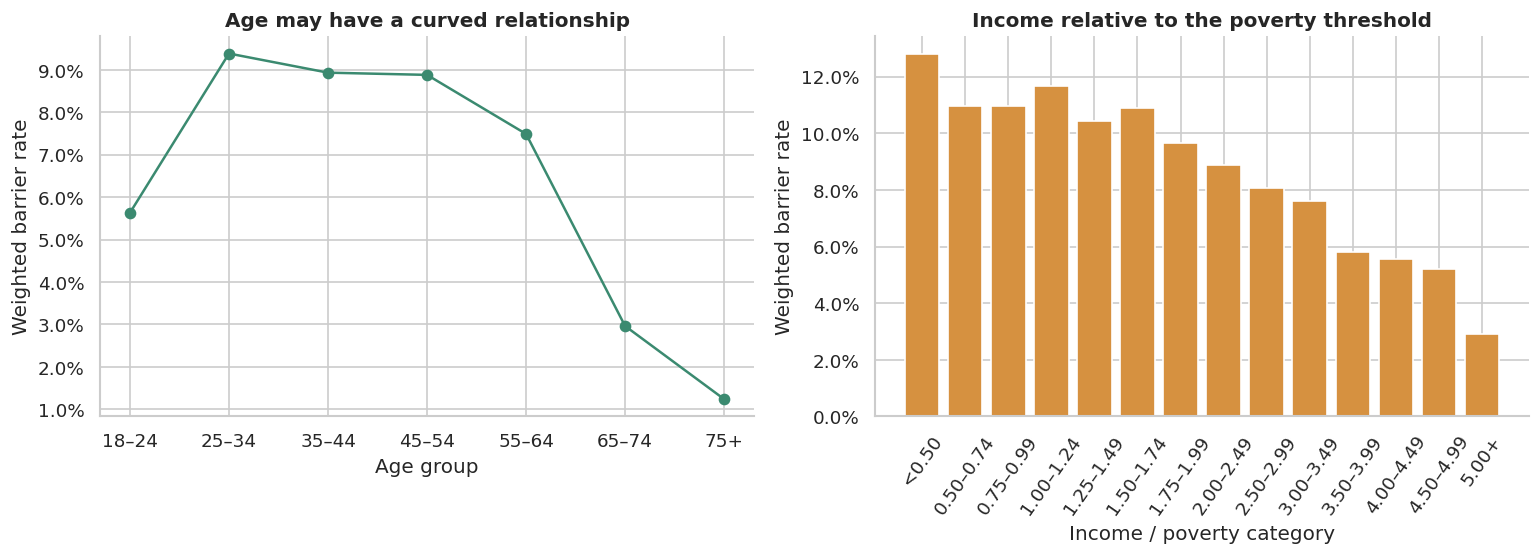

In [7]:
age_data = development.copy()
age_data['AGE_GROUP'] = pd.cut(age_data['AGE'], [17, 24, 34, 44, 54, 64, 74, np.inf],
                               labels=['18–24', '25–34', '35–44', '45–54', '55–64', '65–74', '75+'])
age_rates = age_data.groupby('AGE_GROUP', observed=True).apply(
    lambda g: np.average(g['target'], weights=g['SAMPWEIGHT']), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(age_rates.index.astype(str), age_rates.values, marker='o', color='#3B8A70')
axes[0].set(title='Age may have a curved relationship', xlabel='Age group', ylabel='Weighted barrier rate')
pov_rates = weighted_rate_by(development, 'POVERTY')
axes[1].bar(pov_rates['label'], pov_rates['weighted_rate'], color='#D69140')
axes[1].set(title='Income relative to the poverty threshold', xlabel='Income / poverty category',
            ylabel='Weighted barrier rate')
axes[1].tick_params(axis='x', rotation=55)
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

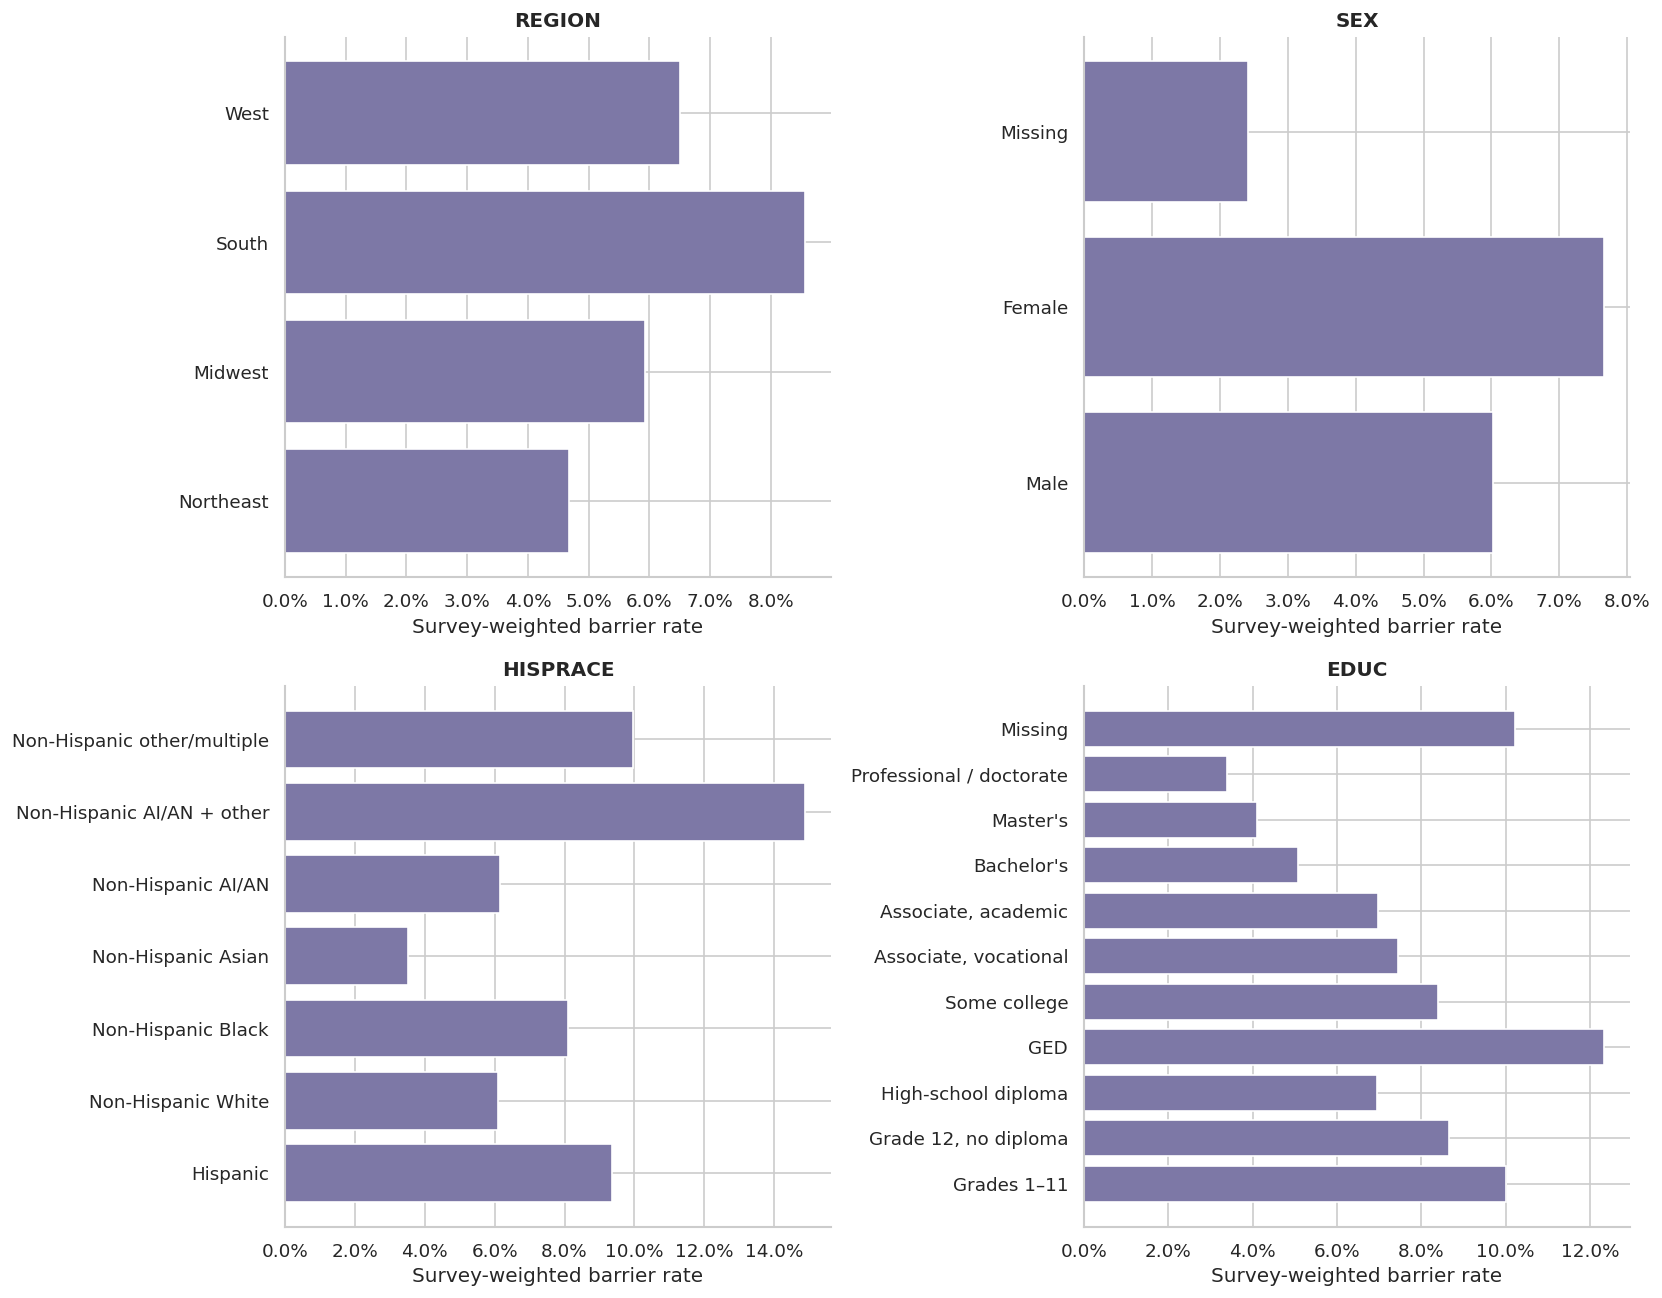

**How we use these charts.** A separate rate for one characteristic does not show what happens after accounting for all the others. We retain the proposed features and let validation assess their combined usefulness. Small demographic groups need cautious interpretation. Race/ethnicity and sex are included as observed descriptors in this research specification; provider use would require a justified policy and checks that prioritisation does not systematically miss groups.

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, column in zip(axes.flat, ['REGION', 'SEX', 'HISPRACE', 'EDUC']):
    rates = weighted_rate_by(development, column)
    ax.barh(rates['label'], rates['weighted_rate'], color='#7D78A6')
    ax.set(title=column, xlabel='Survey-weighted barrier rate')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()
display(Markdown('**How we use these charts.** A separate rate for one characteristic does not show '
                 'what happens after accounting for all the others. We retain the proposed features '
                 'and let validation assess their combined usefulness. Small demographic groups need '
                 'cautious interpretation. Race/ethnicity and sex are included as observed descriptors '
                 'in this research specification; provider use would require a justified policy and '
                 'checks that prioritisation does not systematically miss groups.'))

## Part 5: Hypotheses and Transformations
### Feature selection follows the decision, rather than the easiest correlations

| Input | Business reason to test it |
|---|---|
| `HINOTCOVE` | Coverage may reduce financial exposure, but coverage alone cannot describe all affordability problems |
| `POVERTY` | Income relative to family needs gives information about financial resources |
| `HEALTH` | Self-rated health may distinguish adults with different care needs and financial exposure |
| `USUALPL` | A usual place for care may capture differences in access and care navigation |
| `EMPSTAT` | Employment status may relate to financial circumstances and coverage; not employed does not necessarily mean unemployed |
| `AGE` | Life stage, health needs and coverage arrangements may vary across adulthood |
| `EDUC` | May provide additional socioeconomic information; it does not directly measure financial literacy |
| `REGION` | Regional differences may add information; broad regions do not identify a particular clinic's market |
| `SEX` | May help describe observed differences and assess who the model identifies |
| `HISPRACE` | May capture observed disparities and support subgroup checks; it is not a biological or causal explanation |

**What we exclude and why.** `YBARCARE` and its recoded target would reveal the answer. Person IDs identify respondents rather than need. Survey weights, strata, PSU and sample flags describe how records were sampled. `YEAR` defines the split; we exclude it so the model cannot use year labels as a shortcut. We do not add other unmet-care or delayed-care answers that could simply repeat the target.

**Categorical representation.** The nine survey codes are treated as labels. An education code of 400 does not mean twice the education of code 200. **One-hot encoding** creates a separate Yes/No column for each category. Unknown categories in later data are accepted without relearning the column list. Missing answers get a fixed category; median-age imputation is learned from training rows only.

**Nonlinear age and interactions.** The age chart suggests a curve. Logistic benchmarks test age squared and a smooth age curve called a spline. A random forest can split age at different values and combine insurance, poverty and health through successive branches, so we do not add every possible pair or an age-squared term to the forest. Squaring a nonnegative age preserves its order and adds little to a tree's possible splits. Avoiding hundreds of manual combinations also keeps the feature set understandable.

**Scaling.** Trees do not need standardised inputs to find their splits. We standardise age for logistic benchmarks to make regularised fitting more stable. For descriptive clustering, age is standardised so its units do not overwhelm category differences.

In [9]:
def make_preprocessor(age_mode='raw', columns=None):
    cats = CATEGORICAL if columns is None else [c for c in columns if c != 'AGE']
    parts = []
    if columns is None or 'AGE' in columns:
        age_steps = [('impute', SimpleImputer(strategy='median'))]
        if age_mode == 'quadratic':
            age_steps += [('square', PolynomialFeatures(degree=2, include_bias=False)),
                          ('scale', StandardScaler())]
        elif age_mode == 'spline':
            age_steps += [('spline', SplineTransformer(n_knots=5, degree=3, include_bias=False)),
                          ('scale', StandardScaler())]
        elif age_mode == 'scaled':
            age_steps += [('scale', StandardScaler())]
        parts.append(('age', Pipeline(age_steps), ['AGE']))
    if cats:
        categorical_steps = Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value=-1)),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ])
        parts.append(('category', categorical_steps, cats))
    return ColumnTransformer(parts, remainder='drop')

def model_pipeline(model, age_mode='raw', columns=None):
    return Pipeline([('prepare', make_preprocessor(age_mode, columns)), ('model', model)])

def rank_indices(scores):
    scores = np.asarray(scores, dtype=float)
    if not np.isfinite(scores).all():
        raise ValueError('All scores must be finite.')
    # Fixed random tie order is independent of targets and person IDs.
    ties = np.random.default_rng(RANDOM_STATE).permutation(len(scores))
    return np.lexsort((ties, -scores))

def select_top_k(scores, k):
    k = int(k)
    if not 0 <= k <= len(scores):
        raise ValueError('K must be between 0 and the number scored.')
    selected = np.zeros(len(scores), dtype=bool)
    selected[rank_indices(scores)[:k]] = True
    return selected

def capacity_metrics(y_true, scores, fraction):
    y = np.asarray(y_true, dtype=int)
    k = int(np.ceil(fraction * len(y)))
    selected = select_top_k(scores, k)
    tp = int(y[selected].sum())
    fp = k - tp
    fn = int(y.sum()) - tp
    tn = len(y) - tp - fp - fn
    precision = tp / k if k else 0.0
    recall = tp / y.sum() if y.sum() else 0.0
    return {'capacity': fraction, 'contacts': k, 'cases_found': tp, 'false_positives': fp,
            'missed_cases': fn, 'true_negatives': tn, 'precision': precision,
            'recall': recall, 'lift': precision / y.mean() if y.mean() else np.nan}

def mean_capacity_recall(y_true, scores):
    return float(np.mean([capacity_metrics(y_true, scores, q)['recall']
                          for q in SELECTION_CAPACITIES]))

capacity_scorer = make_scorer(mean_capacity_recall, response_method='predict_proba')
scoring = {'mean_capacity_recall': capacity_scorer, 'AP': 'average_precision', 'ROC_AUC': 'roc_auc'}

def overall_metrics(y, scores):
    return {'AP': average_precision_score(y, scores), 'ROC_AUC': roc_auc_score(y, scores),
            'Brier': brier_score_loss(y, scores)}

def table_at_capacities(y, score_dictionary, capacities=CAPACITIES):
    return pd.DataFrame([{'method': name, **capacity_metrics(y, scores, q)}
                         for name, scores in score_dictionary.items() for q in capacities])

## Part 6: Modelling and Model Selection
### Why random forest is the final model family
A decision tree asks a sequence of questions about characteristics. For example, it can distinguish different health groups within a coverage category. **Random forest averages many trees**, each built using a slightly different set of records and candidate inputs. This can capture curved relationships and combinations of characteristics while reducing reliance on a single unstable tree.

This fits a business problem where insurance status matters, but a combination of financial resources, health and access may identify cases more effectively. It does not guarantee better results than logistic regression. We retain simpler and boosting benchmarks and show where the forest's ranking is competitive. **This analysis focuses on random forest and checks its value against competing approaches at equal capacity. It does not assume that one model must win everywhere.**

### What we compare
Random selection is the minimum benchmark. An **insurance-only logistic model** learns the relationship between coverage category and the target from training data; everybody with the same category gets the same score, so ties are resolved using a fixed random order. This answers whether the extra nine characteristics add useful information. A constant-probability model cannot distinguish people and behaves like random selection when ties are broken.

Additional references are logistic regression with age squared, logistic regression with age splines, a single tree and gradient boosting. We use the same ten original inputs and same development split. Benchmarks are useful controls, rather than an exhaustive search of every algorithm.

### Evaluation follows the provider's decision
For a population with N adults, let **K = available contacts**. We rank by scores and contact K adults. In the scenario tables K is the rounded-up scenario fraction of N; in practice the provider supplies an integer K.

| Measure | Business meaning |
|---|---|
| Precision at K = cases found / contacts | How many contacts identify a reported barrier; relates to follow-up workload |
| Recall at K = cases found / all actual cases | How much of the total reported need the list captures |
| Lift at K = precision / overall barrier rate | How concentrated the list is compared with random selection |
| False positives | Selected adults who did not report this particular target outcome |
| False negatives / missed cases | Actual reported cases outside the contact list |
| Average precision (AP) | A broader summary of how well positive cases are ranked; higher is better, but it is not accuracy |
| ROC-AUC | Overall separation of cases and non-cases; secondary because non-cases are numerous |

At the **same K and same sample**, finding more cases improves precision, recall and lift together. Comparing a 5% list with a 30% list would confound model quality with extra contacts. Accuracy and the default 0.50 cutoff are therefore not the primary business criteria. F1/F2 are also not used to invent a contact capacity.

### A transparent provisional selection rule
An actual provider budget is unknown. To select forest settings reproducibly, we use **mean recall across 5%, 10% and 20% capacity scenarios**, with equal weights. These represent a range of limited-capacity situations; their equal weighting is an **analytical convention**, not established staffing data or a finding that these are the best budgets. We also show the full capacity curves and AP. A provider should reconfirm the choice at its actual K.

We first rank forest settings using **five-fold CV on 2023** and carry the best three settings to **2024 validation**. The final forest has the highest validation mean recall across those same scenarios; AP breaks an exact tie, followed by a simpler setting. Benchmark settings are tuned using the same CV criterion. **No 2025 score is used to choose a model, settings, capacity or profile.**

### Regularisation and class imbalance
**Overfitting** means learning details that do not transfer well to new respondents. Minimum leaf size stops a tree from creating very small groups; depth limits how many successive questions it can ask. We test leaf sizes of 20 or 80 and a depth limit of 8 or no fixed depth limit. Even an unlimited-depth tree is constrained by the minimum leaf size. We retain 150 trees, as in the original approach, to keep computation manageable.

We also test ordinary fitting against `balanced_subsample`, which gives rare positive cases more weight when each tree is fitted. Class weighting is a candidate setting, not a guarantee of fewer missed cases at the **same contact capacity**. If balancing is selected, it changes the importance of positive cases during training, so returned values should be treated as **ranking scores rather than reliable population probabilities**. We do not duplicate rare cases or discard non-cases before CV. Every held-out fold keeps its natural prevalence.

Primary fitting and workload metrics are **unweighted by survey weights**: each respondent represents one potential contact in this simulated list. `SAMPWEIGHT` is used for population-oriented EDA and a secondary sensitivity table. This is a respondent-list proof of concept, not a nationally optimised outreach programme. A provider would retrain and evaluate on its own patient population.

In [10]:
assert not TEST_OPENED
forest_search = GridSearchCV(
    model_pipeline(RandomForestClassifier(n_estimators=150, max_features='sqrt',
                                          n_jobs=1, random_state=RANDOM_STATE)),
    {'model__max_depth': [8, None], 'model__min_samples_leaf': [20, 80],
     'model__class_weight': [None, 'balanced_subsample']},
    scoring=scoring, refit='mean_capacity_recall', cv=cv, n_jobs=N_JOBS,
    error_score='raise', return_train_score=False)
started = time.perf_counter()
fit_development(forest_search, X_train, y_train, initial_train, '2023 forest five-fold grid search')
cv_results = pd.DataFrame(forest_search.cv_results_).sort_values(
    ['mean_test_mean_capacity_recall', 'mean_test_AP'], ascending=False)
display(cv_results[['params', 'mean_test_mean_capacity_recall',
                    'std_test_mean_capacity_recall', 'mean_test_AP']].reset_index(drop=True))
print(f'Completed forest CV in {time.perf_counter() - started:.1f} seconds.')

forest_finalists, forest_scores, forest_rows = {}, {}, []
for number, (_, row) in enumerate(cv_results.head(3).iterrows(), start=1):
    name = f'Forest finalist {number}'
    estimator = clone(forest_search.estimator).set_params(**row['params'])
    fit_development(estimator, X_train, y_train, initial_train, name + ': 2023 fit')
    scores = estimator.predict_proba(X_validation)[:, 1]
    forest_finalists[name], forest_scores[name] = estimator, scores
    forest_rows.append({'name': name, 'parameters': row['params'],
                        'depth_order': 0 if row['params']['model__max_depth'] == 8 else 1,
                        'leaf_size': row['params']['model__min_samples_leaf'],
                        'validation_mean_recall': mean_capacity_recall(y_validation, scores),
                        'CV_mean_recall': row['mean_test_mean_capacity_recall'],
                        **overall_metrics(y_validation, scores)})
forest_comparison = pd.DataFrame(forest_rows).sort_values(
    ['validation_mean_recall', 'AP', 'depth_order', 'leaf_size', 'name'],
    ascending=[False, False, True, False, True]).reset_index(drop=True)
selected_forest_name = forest_comparison.iloc[0]['name']
selected_validation_model = forest_finalists[selected_forest_name]
selected_validation_scores = forest_scores[selected_forest_name]
display(forest_comparison)
print('Chosen forest:', selected_forest_name)
print('Chosen parameters:', selected_validation_model.named_steps['model'].get_params())

Completed forest CV in 58.7 seconds.
Chosen forest: Forest finalist 1
Chosen parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced_subsample', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 20, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 150, 'n_jobs': 1, 'oob_score': False, 'random_state': 1, 'verbose': 0, 'warm_start': False}


,params,mean_test_mean_capacity_recall,std_test_mean_capacity_recall,mean_test_AP
0,"{'model__class_weight': 'balanced_subsample', ...",0.4048,0.0102,0.2215
1,"{'model__class_weight': None, 'model__max_dept...",0.4013,0.0111,0.2202
2,"{'model__class_weight': 'balanced_subsample', ...",0.4011,0.0133,0.2196
3,"{'model__class_weight': 'balanced_subsample', ...",0.3967,0.0099,0.2142
4,"{'model__class_weight': None, 'model__max_dept...",0.3963,0.0113,0.2103
5,"{'model__class_weight': None, 'model__max_dept...",0.3949,0.0107,0.2186
6,"{'model__class_weight': 'balanced_subsample', ...",0.3945,0.0116,0.2126
7,"{'model__class_weight': None, 'model__max_dept...",0.3881,0.0109,0.2094


,name,parameters,depth_order,leaf_size,validation_mean_recall,CV_mean_recall,AP,ROC_AUC,Brier
0,Forest finalist 1,"{'model__class_weight': 'balanced_subsample', ...",1,20,0.3678,0.4048,0.2093,0.7656,0.1530
1,Forest finalist 2,"{'model__class_weight': None, 'model__max_dept...",1,20,0.3658,0.4013,0.2119,0.7623,0.0586
2,Forest finalist 3,"{'model__class_weight': 'balanced_subsample', ...",0,20,0.3658,0.4011,0.2090,0.7677,0.1797


In [11]:
benchmark_specs = [
    ('Logistic: age squared', model_pipeline(LogisticRegression(max_iter=2500), 'quadratic'),
     {'model__C': [0.1, 1.0, 10.0]}),
    ('Logistic: age splines', model_pipeline(LogisticRegression(max_iter=2500), 'spline'),
     {'model__C': [0.1, 1.0, 10.0]}),
    ('Single decision tree', model_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
     {'model__max_depth': [3, 5], 'model__min_samples_leaf': [100, 300]}),
    ('Gradient boosting', model_pipeline(HistGradientBoostingClassifier(
        max_iter=120, early_stopping=False, l2_regularization=1.0, random_state=RANDOM_STATE)),
     {'model__max_leaf_nodes': [7, 15], 'model__learning_rate': [0.05, 0.10]})
]
benchmark_searches, validation_score_dictionary = {}, {'Random forest': selected_validation_scores}
benchmark_rows = []
for name, estimator, grid in benchmark_specs:
    search = GridSearchCV(estimator, grid, scoring=scoring, refit='mean_capacity_recall',
                          cv=cv, n_jobs=N_JOBS, error_score='raise')
    fit_development(search, X_train, y_train, initial_train, name + ': 2023 CV')
    scores = search.predict_proba(X_validation)[:, 1]
    benchmark_searches[name] = search
    validation_score_dictionary[name] = scores
    benchmark_rows.append({'method': name, 'best_settings': search.best_params_,
                           'CV_mean_recall': search.best_score_,
                           'validation_mean_recall': mean_capacity_recall(y_validation, scores),
                           **overall_metrics(y_validation, scores)})
    print('Completed', name)

insurance_validation_model = model_pipeline(
    LogisticRegression(C=1.0, max_iter=2500), columns=['HINOTCOVE'])
fit_development(insurance_validation_model, X_train, y_train, initial_train, 'Insurance-only baseline: 2023')
constant_validation_model = DummyClassifier(strategy='prior')
fit_development(constant_validation_model, X_train, y_train, initial_train, 'Constant baseline: 2023')
validation_score_dictionary['Insurance only'] = insurance_validation_model.predict_proba(X_validation)[:, 1]
validation_score_dictionary['Constant score / random tie order'] = constant_validation_model.predict_proba(X_validation)[:, 1]

comparison = pd.DataFrame([{'method': 'Random forest', 'best_settings': forest_comparison.iloc[0]['parameters'],
                            'CV_mean_recall': forest_comparison.iloc[0]['CV_mean_recall'],
                            'validation_mean_recall': mean_capacity_recall(y_validation, selected_validation_scores),
                            **overall_metrics(y_validation, selected_validation_scores)}] + benchmark_rows)
display(comparison.sort_values('validation_mean_recall', ascending=False))
validation_capacity_table = table_at_capacities(y_validation, validation_score_dictionary)
display(validation_capacity_table.loc[validation_capacity_table['capacity'].isin(SELECTION_CAPACITIES),
    ['method', 'capacity', 'contacts', 'cases_found', 'precision', 'recall', 'lift']])

Completed Logistic: age squared
Completed Logistic: age splines
Completed Single decision tree
Completed Gradient boosting


,method,best_settings,CV_mean_recall,validation_mean_recall,AP,ROC_AUC,Brier
0,Random forest,"{'model__class_weight': 'balanced_subsample', ...",0.4048,0.3678,0.2093,0.7656,0.1530
4,Gradient boosting,"{'model__learning_rate': 0.1, 'model__max_leaf...",0.4101,0.3666,0.2174,0.7713,0.0583
1,Logistic: age squared,{'model__C': 1.0},0.4136,0.3658,0.2191,0.7704,0.0583
2,Logistic: age splines,{'model__C': 1.0},0.4130,0.3651,0.2194,0.7715,0.0583
3,Single decision tree,"{'model__max_depth': 5, 'model__min_samples_le...",0.3755,0.3472,0.1854,0.7416,0.0589


,method,capacity,contacts,cases_found,precision,recall,lift
0,Random forest,0.0500,1618,462,0.2855,0.2105,4.2088
1,Random forest,0.1000,3236,780,0.2410,0.3554,3.5529
2,Random forest,0.2000,6471,1180,0.1824,0.5376,2.6878
6,Logistic: age squared,0.0500,1618,485,0.2998,0.2210,4.4183
7,Logistic: age squared,0.1000,3236,755,0.2333,0.3440,3.4390
8,Logistic: age squared,0.2000,6471,1169,0.1807,0.5326,2.6628
12,Logistic: age splines,0.0500,1618,475,0.2936,0.2164,4.3272
13,Logistic: age splines,0.1000,3236,763,0.2358,0.3476,3.4754
14,Logistic: age splines,0.2000,6471,1166,0.1802,0.5312,2.6560
18,Single decision tree,0.0500,1618,467,0.2886,0.2128,4.2543


In [12]:
selection_best = comparison.sort_values('validation_mean_recall', ascending=False).iloc[0]
rf_summary = comparison.loc[comparison['method'].eq('Random forest')].iloc[0]
display(Markdown(f"**Selection interpretation.** {selected_forest_name} is the chosen forest setting, "
                 f"with mean 2024 recall of **{rf_summary['validation_mean_recall']:.1%}** across the "
                 '5%, 10% and 20% scenarios. This selects a forest configuration rather than a provider budget. '
                 f"The strongest benchmark-family mean in this run belongs to **{selection_best['method']}** "
                 f"({selection_best['validation_mean_recall']:.1%}). "
                 'Read the capacity-specific table before claiming one family is best. Small differences '
                 'are descriptive and are not evidence of a statistically significant advantage. '
                 'Random forest is the focal model, with competitive benchmarks reported alongside it.'))
display(Markdown("**Why this criterion fits the decision.** The provider wants to find more reported cases using the same number of contacts. Mean recall across several capacity scenarios gives a provisional comparison while the real budget is unknown. The final capacity tables remain essential: a slightly higher average is not proof that the same model is best at a particular provider's contact limit."))

**Selection interpretation.** Forest finalist 1 is the chosen forest setting, with mean 2024 recall of **36.8%** across the 5%, 10% and 20% scenarios. This selects a forest configuration rather than a provider budget. The strongest benchmark-family mean in this run belongs to **Random forest** (36.8%). Read the capacity-specific table before claiming one family is best. Small differences are descriptive and are not evidence of a statistically significant advantage. Random forest is the focal model, with competitive benchmarks reported alongside it.

**Why this criterion fits the decision.** The provider wants to find more reported cases using the same number of contacts. Mean recall across several capacity scenarios gives a provisional comparison while the real budget is unknown. The final capacity tables remain essential: a slightly higher average is not proof that the same model is best at a particular provider's contact limit.

## Part 7: Model Diagnostics and Business Plausibility
### Do the predictions help with the actual decision?
The following diagnostics use the model fitted on 2023 and checked on 2024. A cumulative-gains curve shows what share of cases is found as more adults are contacted. Precision shows the yield per contact; lift compares that yield with random selection. Better models are compared **at the same horizontal position**.

We also inspect precision–recall, score reliability and original-variable importance. Regression residual normality is not a requirement for a binary classifier, so the wage example's normal Q–Q plot is not copied mechanically.

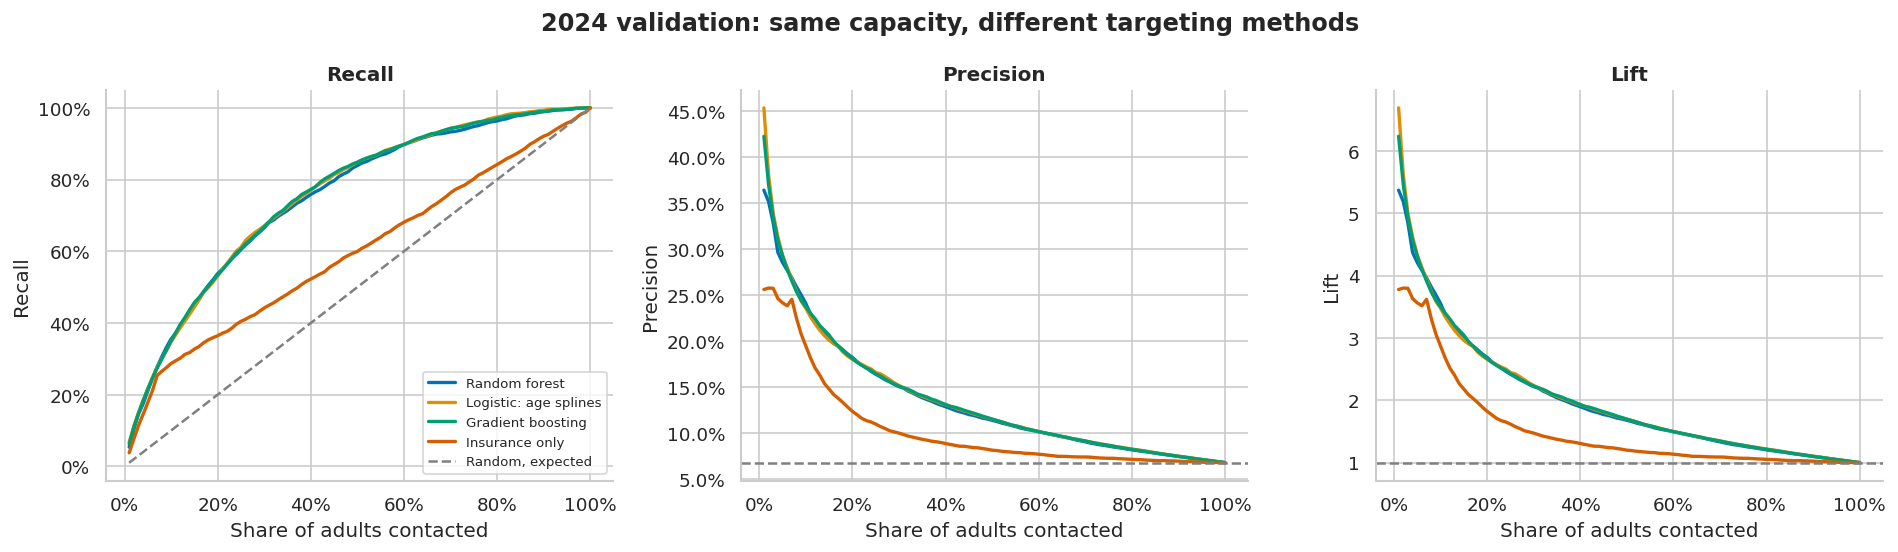

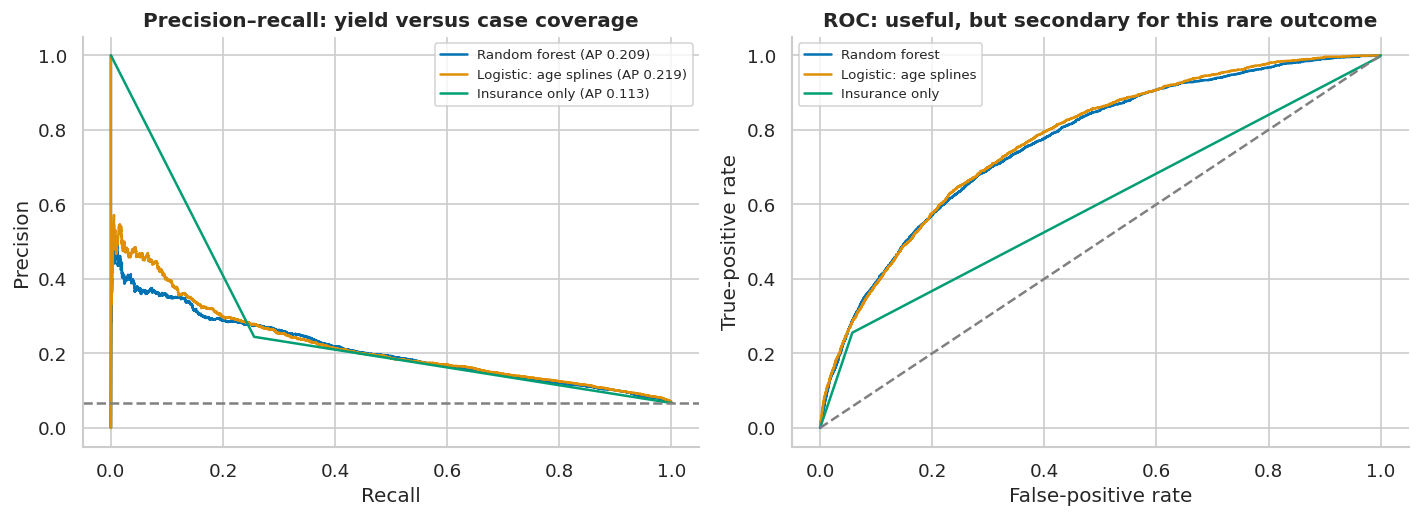

In [13]:
def plot_capacity_curves(y, score_dictionary, title):
    fractions = np.linspace(0.01, 1.0, 100)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.7))
    for name, scores in score_dictionary.items():
        metrics = pd.DataFrame([capacity_metrics(y, scores, q) for q in fractions])
        for ax, measure in zip(axes, ['recall', 'precision', 'lift']):
            ax.plot(metrics['capacity'], metrics[measure], label=name, linewidth=2)
    axes[0].plot(fractions, fractions, '--', color='grey', label='Random, expected')
    axes[1].axhline(np.mean(y), linestyle='--', color='grey')
    axes[2].axhline(1, linestyle='--', color='grey')
    for ax, measure in zip(axes, ['recall', 'precision', 'lift']):
        ax.set(xlabel='Share of adults contacted', ylabel=measure.capitalize(), title=measure.capitalize())
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        if measure != 'lift': ax.yaxis.set_major_formatter(PercentFormatter(1))
    axes[0].legend(fontsize=8)
    fig.suptitle(title, weight='bold')
    plt.tight_layout(); plt.show()

plot_capacity_curves(y_validation, {name: validation_score_dictionary[name] for name in
    ['Random forest', 'Logistic: age splines', 'Gradient boosting', 'Insurance only']},
    '2024 validation: same capacity, different targeting methods')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in ['Random forest', 'Logistic: age splines', 'Insurance only']:
    scores = validation_score_dictionary[name]
    precision, recall, _ = precision_recall_curve(y_validation, scores)
    axes[0].plot(recall, precision, label=f'{name} (AP {average_precision_score(y_validation, scores):.3f})')
    fpr, tpr, _ = roc_curve(y_validation, scores)
    axes[1].plot(fpr, tpr, label=name)
axes[0].axhline(y_validation.mean(), linestyle='--', color='grey')
axes[0].set(title='Precision–recall: yield versus case coverage', xlabel='Recall', ylabel='Precision')
axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], '--', color='grey')
axes[1].set(title='ROC: useful, but secondary for this rare outcome',
            xlabel='False-positive rate', ylabel='True-positive rate')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

,sample,AP,ROC_AUC,Brier
0,2023 fitted rows (optimistic),0.3198,0.8703,0.1438
1,2024 validation,0.2093,0.7656,0.1530


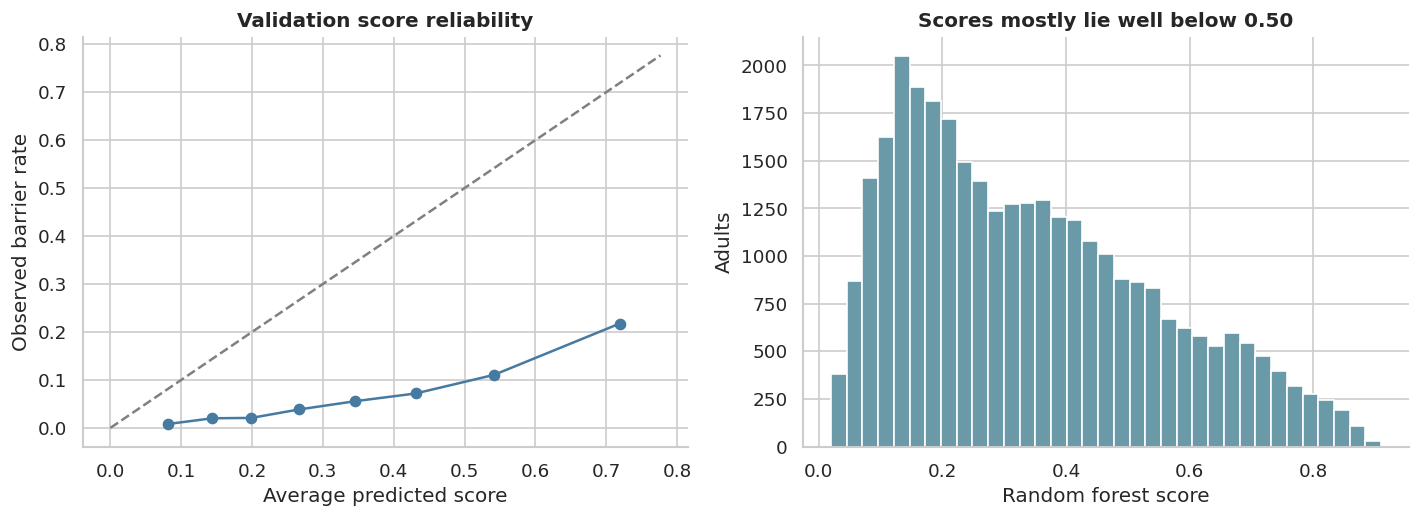

**Interpretation.** Training scores are measured on examples the model already saw, so they can look better than later-year validation. A score of 0.20 should not automatically be interpreted as a reliable 20% individual risk. Calibration checks whether score groups match observed rates; it is distinct from ranking quality. We use scores to order the contact list and do not calibrate or retune after examining 2025.

In [14]:
train_scores = selected_validation_model.predict_proba(X_train)[:, 1]
display(pd.DataFrame([
    {'sample': '2023 fitted rows (optimistic)', **overall_metrics(y_train, train_scores)},
    {'sample': '2024 validation', **overall_metrics(y_validation, selected_validation_scores)}]))
observed, predicted = calibration_curve(y_validation, selected_validation_scores, n_bins=8, strategy='quantile')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(predicted, observed, marker='o', color='#467AA0')
bound = max(max(predicted), max(observed)) * 1.08
axes[0].plot([0, bound], [0, bound], '--', color='grey')
axes[0].set(title='Validation score reliability', xlabel='Average predicted score',
            ylabel='Observed barrier rate')
axes[1].hist(selected_validation_scores, bins=35, color='#6A99A8')
axes[1].set(title='Scores mostly lie well below 0.50', xlabel='Random forest score', ylabel='Adults')
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation.** Training scores are measured on examples the model already saw, '
                 'so they can look better than later-year validation. A score of 0.20 should not '
                 'automatically be interpreted as a reliable 20% individual risk. Calibration checks '
                 'whether score groups match observed rates; it is distinct from ranking quality. '
                 'We use scores to order the contact list and do not calibrate or retune after examining 2025.'))

### Reading the selected forest's scores correctly
The validation reliability curve lies well below the diagonal: **the weighted forest's scores are higher than the observed barrier rates**. Giving rare cases extra training weight helped its ranking criterion, but its returned scores are poorly calibrated. We should therefore say “this adult ranks higher for follow-up”, rather than tell somebody that their score is their actual probability of needing support.

The **Brier score** averages the squared gap between a score and the known 0/1 answer; lower is better. The forest's worse Brier score than the unweighted benchmarks is a real limitation. It is retained here for the **contact-ranking decision**, where the score order matters. This would be a different choice if the provider needed reliable individual probability estimates. No probability calibration is learned from 2025.

For the logistic benchmarks, **regularisation** limits unusually large fitted effects to reduce overfitting. The tested `C` values are 0.1, 1 and 10; a smaller `C` means a stronger penalty. The spline benchmark uses a modest five-knot age curve to allow flexibility while keeping the comparison manageable. These benchmarks help check whether the forest adds enough value to justify its complexity.

,predictor,validation_AP_drop,shuffle_SD
9,HINOTCOVE,0.0682,0.0014
7,HEALTH,0.0458,0.0018
1,AGE,0.0350,0.0009
6,POVERTY,0.0129,0.0012
2,SEX,0.0066,0.0020
8,USUALPL,0.0036,0.0019
3,HISPRACE,0.0032,0.0007
5,EMPSTAT,0.0011,0.0006
0,REGION,0.0002,0.0017
4,EDUC,0.0001,0.0004


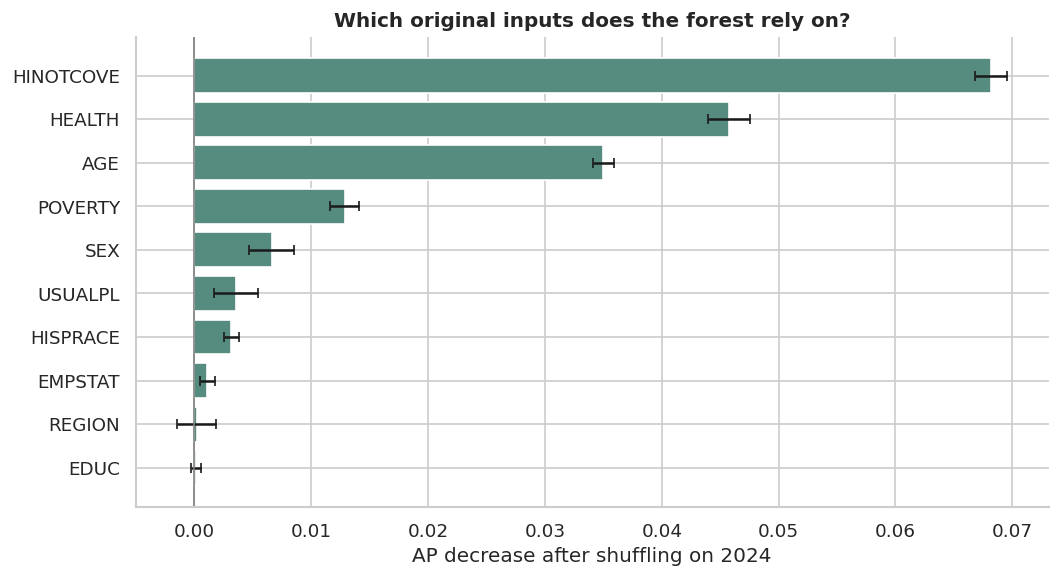

**Business interpretation.** Shuffling one original variable breaks its useful connection with other information while leaving the fitted model fixed. A larger drop means this model relies more on that variable for ranking. Here the largest drops are for **HINOTCOVE, HEALTH, AGE**. This supports checking whether those inputs are available and recorded consistently in a provider setting. Importance does not show the direction of an effect or prove causation. Correlated inputs can share information; a small drop is not proof that a characteristic never matters. Error bars show repeated shuffles, not statistical confidence intervals.

In [15]:
importance_result = permutation_importance(
    selected_validation_model, X_validation, y_validation, scoring='average_precision',
    n_repeats=4, random_state=RANDOM_STATE, n_jobs=N_JOBS)
importance_table = pd.DataFrame({'predictor': PREDICTORS,
    'validation_AP_drop': importance_result.importances_mean,
    'shuffle_SD': importance_result.importances_std}).sort_values('validation_AP_drop', ascending=False)
display(importance_table)
plot_importance = importance_table.sort_values('validation_AP_drop')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_importance['predictor'], plot_importance['validation_AP_drop'],
        xerr=plot_importance['shuffle_SD'], color='#568B80', capsize=3)
ax.axvline(0, color='grey', linewidth=1)
ax.set(title='Which original inputs does the forest rely on?', xlabel='AP decrease after shuffling on 2024')
plt.tight_layout(); plt.show()
display(Markdown('**Business interpretation.** Shuffling one original variable breaks its useful '
                 'connection with other information while leaving the fitted model fixed. A larger '
                 'drop means this model relies more on that variable for ranking. Here the largest '
                 'drops are for **' + ', '.join(importance_table.head(3)['predictor']) + '**. '
                 'This supports checking whether those inputs are available and recorded consistently '
                 'in a provider setting. Importance does not show the direction of an effect or prove '
                 'causation. Correlated inputs can share information; a small drop is not proof that '
                 'a characteristic never matters. Error bars show repeated shuffles, not statistical confidence intervals.'))

In [16]:
def subgroup_report(records, scores, fraction):
    selected = select_top_k(scores, int(np.ceil(len(records) * fraction)))
    d = records.copy().assign(selected=selected)
    rows = []
    for column in ['HINOTCOVE', 'SEX', 'HISPRACE']:
        for value, group in d.groupby(column, dropna=False):
            tp = int(group.loc[group['selected'], 'target'].sum())
            cases = int(group['target'].sum())
            contacts = int(group['selected'].sum())
            rows.append({'variable': column, 'group': category_label(value, column), 'adults': len(group),
                          'actual_cases': cases, 'contacts': contacts, 'cases_found': tp,
                          'selection_rate': contacts / len(group),
                          'recall': tp / cases if cases else np.nan,
                          'precision': tp / contacts if contacts else np.nan})
    return pd.DataFrame(rows)

validation_subgroups = subgroup_report(validation, selected_validation_scores, 0.10)
display(validation_subgroups)
display(Markdown('**Subgroup check, illustrative 10% scenario.** The same overall contact list is '
                 'used for every group; each group is not assigned a separate quota. Group recall '
                 'shows which reported cases the procedure misses. Differences should be reviewed '
                 'alongside group sample sizes and prevalence. They are descriptive checks, not a '
                 'complete fairness assessment or a reason to infer individual need from group membership.'))

,variable,group,adults,actual_cases,contacts,cases_found,selection_rate,recall,precision
0,HINOTCOVE,Covered,29980,1625,1259,254,0.0420,0.1563,0.2017
1,HINOTCOVE,Not covered,2295,561,1975,526,0.8606,0.9376,0.2663
2,HINOTCOVE,Missing,79,9,2,0,0.0253,0.0000,0.0000
3,SEX,Male,14850,903,1319,311,0.0888,0.3444,0.2358
4,SEX,Female,17499,1292,1917,469,0.1095,0.3630,0.2447
5,SEX,Missing,5,0,0,0,0.0000,NaN,NaN
6,HISPRACE,Hispanic,4712,439,1074,253,0.2279,0.5763,0.2356
7,HISPRACE,Non-Hispanic White,21631,1350,1547,392,0.0715,0.2904,0.2534
8,HISPRACE,Non-Hispanic Black,3234,241,399,85,0.1234,0.3527,0.2130
9,HISPRACE,Non-Hispanic Asian,1851,62,65,11,0.0351,0.1774,0.1692


**Subgroup check, illustrative 10% scenario.** The same overall contact list is used for every group; each group is not assigned a separate quota. Group recall shows which reported cases the procedure misses. Differences should be reviewed alongside group sample sizes and prevalence. They are descriptive checks, not a complete fairness assessment or a reason to infer individual need from group membership.

### Priority-population profiles: a separate descriptive task
Classification answers **who to rank first**; segmentation asks **what kinds of people appear in a priority population**. Clustering does not replace the classifier, and it does not establish which intervention will work.

To make this second task concrete, we use the highest-scoring **20% of the 2024 validation sample as an illustrative planning population**. This is a scope for describing profiles, not a mandatory contact budget. The adults were scored by a forest fitted only on 2023, so their own outcomes did not teach the model that generated these scores. We later show how profile shares change at other capacities.

We use **k-prototypes**, which groups people using both numeric age and categorical answers. Age is standardised within this development planning population. Category mismatches receive a fixed weight of 0.5; this balances age differences with categorical differences and is a modelling convention, not a learned measure of support need.

The clustering inputs are **age, poverty, health, insurance, usual place of care, employment and education**. These cover life stage, financial circumstances, health and access. Race, sex and region are left out of the clustering distance so they do not directly define outreach-support profiles. Targets, scores, weights, year and identifiers are also excluded. An insured or relatively higher-income profile can still appear because the original priority list uses combined information.

We compare 2–5 clusters using separation (silhouette), minimum group size and stability across repeated starts (adjusted Rand index, ARI). These assess descriptive usefulness, not predictive accuracy. We prefer the smallest stable solution within 0.02 of the best silhouette, with each group at least 5% of the planning pool. Stability of 0.60 is an exploratory screen, not a universal standard. Target rates are inspected **only after** this choice and never used to select the clusters.

In [17]:
assert not TEST_OPENED
PROFILE_COLUMNS = ['AGE', 'POVERTY', 'HEALTH', 'HINOTCOVE', 'USUALPL', 'EMPSTAT', 'EDUC']
PROFILE_CATS = PROFILE_COLUMNS[1:]
PROFILE_CAT_INDEX = list(range(1, len(PROFILE_COLUMNS)))
assert set(PROFILE_COLUMNS).isdisjoint(EXCLUDED + ['score'])
planning_mask = select_top_k(selected_validation_scores, int(np.ceil(PROFILE_FRACTION * len(validation))))
planning_pool = validation.loc[planning_mask].copy().reset_index(drop=True)
profile_age_imputer = SimpleImputer(strategy='median')
profile_age_scaler = StandardScaler()
profile_age = profile_age_scaler.fit_transform(profile_age_imputer.fit_transform(planning_pool[['AGE']]))
FIT_LOG.append({'step': 'Profile age imputer and scaler', 'years': [2024], 'rows': len(planning_pool)})

def profile_matrix(records):
    age = profile_age_scaler.transform(profile_age_imputer.transform(records[['AGE']])).ravel()
    cats = records[PROFILE_CATS].fillna(-1).astype(int).astype(str).to_numpy()
    matrix = np.empty((len(records), len(PROFILE_COLUMNS)), dtype=object)
    matrix[:, 0] = age
    matrix[:, 1:] = cats
    return matrix

planning_matrix = profile_matrix(planning_pool)
rng = np.random.default_rng(RANDOM_STATE)
silhouette_idx = rng.choice(len(planning_pool), min(800, len(planning_pool)), replace=False)
small_matrix = planning_matrix[silhouette_idx]
small_age = small_matrix[:, 0].astype(float)
profile_distance = (small_age[:, None] - small_age[None, :]) ** 2
for j in PROFILE_CAT_INDEX:
    profile_distance += 0.5 * (small_matrix[:, j, None] != small_matrix[None, :, j])
np.fill_diagonal(profile_distance, 0.0)

cluster_candidates, cluster_rows = {}, []
for k in range(2, 6):
    model = KPrototypes(n_clusters=k, init='Huang', n_init=3, max_iter=40,
                        gamma=0.5, random_state=RANDOM_STATE, n_jobs=1, verbose=0)
    labels = model.fit_predict(planning_matrix, categorical=PROFILE_CAT_INDEX)
    FIT_LOG.append({'step': f'Profile k={k}', 'years': [2024], 'rows': len(planning_pool)})
    repeat_labels = []
    for seed in [17, 41]:
        repeat = KPrototypes(n_clusters=k, init='Huang', n_init=2, max_iter=40,
                             gamma=0.5, random_state=seed, n_jobs=1, verbose=0)
        repeat_labels.append(repeat.fit_predict(planning_matrix, categorical=PROFILE_CAT_INDEX))
        FIT_LOG.append({'step': f'Profile stability k={k}, seed={seed}', 'years': [2024], 'rows': len(planning_pool)})
    stability = np.mean([adjusted_rand_score(labels, repeat) for repeat in repeat_labels])
    sizes = np.bincount(labels, minlength=k) / len(labels)
    silhouette = silhouette_score(profile_distance, labels[silhouette_idx], metric='precomputed')
    cluster_candidates[k] = model
    cluster_rows.append({'k': k, 'silhouette': silhouette, 'start_stability_ARI': stability,
                         'smallest_share': sizes.min(), 'within_cluster_cost': model.cost_})
cluster_diagnostics = pd.DataFrame(cluster_rows)
eligible = cluster_diagnostics.loc[(cluster_diagnostics['smallest_share'] >= 0.05) &
                                    (cluster_diagnostics['start_stability_ARI'] >= 0.60)]
profiles_stable = not eligible.empty
if eligible.empty:
    eligible = cluster_diagnostics.copy()
best_silhouette = eligible['silhouette'].max()
chosen_k = int(eligible.loc[eligible['silhouette'] >= best_silhouette - 0.02, 'k'].min())
profile_model = cluster_candidates[chosen_k]
planning_clusters = profile_model.predict(planning_matrix, categorical=PROFILE_CAT_INDEX)
cluster_age_order = planning_pool.assign(cluster=planning_clusters).groupby('cluster')['AGE'].mean().sort_values().index
PROFILE_NAMES = {int(cluster): f'Profile {chr(65+i)}' for i, cluster in enumerate(cluster_age_order)}
display(cluster_diagnostics)
print(f'Planning adults: {len(planning_pool):,}; chosen clusters: {chosen_k}; stability screen passed: {profiles_stable}')

Planning adults: 6,471; chosen clusters: 2; stability screen passed: True


,k,silhouette,start_stability_ARI,smallest_share,within_cluster_cost
0,2,0.4740,1.0000,0.4100,"11,828.0075"
1,3,0.3073,0.6079,0.2755,"10,664.3156"
2,4,0.1878,0.5305,0.2066,"9,983.1171"
3,5,0.1856,0.4859,0.1218,"9,763.3183"


,profile,adults,share,median_age,uninsured,income_below_2x_poverty,fair_or_poor_health,no_usual_place,not_employed,reported_barrier_rate
0,Profile A,3818,0.5900,34.0000,0.4125,0.5003,0.2135,0.2928,0.1967,0.1894
1,Profile B,2653,0.4100,57.0000,0.2574,0.5922,0.6087,0.1470,0.5194,0.1723


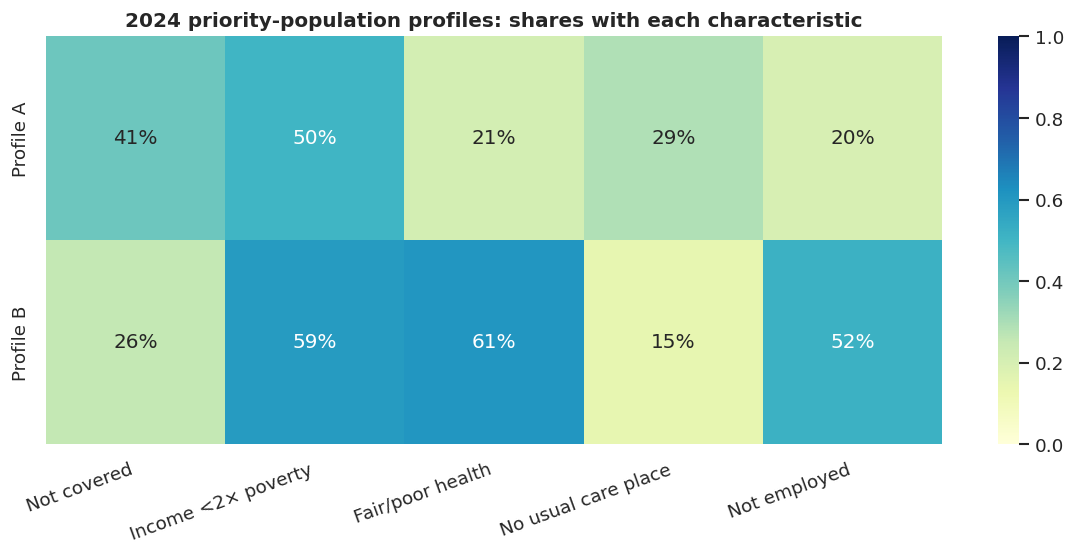

profile,possible_outreach_focus
Profile A,Ask about current cost barriers and explain available assistance pathways. Explore help connecting to a regular source of care.
Profile B,Review cost concerns alongside care navigation and existing coverage. Coordinate follow-up with the existing care team where appropriate.


**How to use the profiles.** The table describes group averages; individuals within a profile can have different needs. Suggested outreach focuses are hypotheses for a provider to assess, not interventions shown to work by these data. Clustering does not verify a positive prediction. The reported-barrier rate was added only after the groups were fixed, so it did not determine their number or membership. Restart stability is not evidence that these groups will remain stable in another provider.

In [18]:
LOWER_INCOME_CODES = [11, 12, 13, 21, 22, 23, 24]

def profile_summary(records, cluster_labels):
    data = records.assign(profile=[PROFILE_NAMES[int(c)] for c in cluster_labels])
    rows = []
    for name, g in data.groupby('profile'):
        rows.append({'profile': name, 'adults': len(g), 'share': len(g) / len(data),
                      'median_age': g['AGE'].median(),
                      'uninsured': g['HINOTCOVE'].eq(2).mean(),
                      'income_below_2x_poverty': g['POVERTY'].isin(LOWER_INCOME_CODES).mean(),
                      'fair_or_poor_health': g['HEALTH'].isin([4, 5]).mean(),
                      'no_usual_place': g['USUALPL'].eq(1).mean(),
                      'not_employed': g['EMPSTAT'].eq(200).mean(),
                      'reported_barrier_rate': g['target'].mean()})
    return pd.DataFrame(rows)

planning_profile_summary = profile_summary(planning_pool, planning_clusters)
display(planning_profile_summary)
profile_plot_columns = ['uninsured', 'income_below_2x_poverty', 'fair_or_poor_health',
                         'no_usual_place', 'not_employed']
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(planning_profile_summary.set_index('profile')[profile_plot_columns],
            annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=1, ax=ax)
ax.set(title='2024 priority-population profiles: shares with each characteristic', xlabel='', ylabel='')
ax.set_xticklabels(['Not covered', 'Income <2× poverty', 'Fair/poor health',
                    'No usual care place', 'Not employed'], rotation=20, ha='right')
plt.tight_layout(); plt.show()

def support_hypotheses(summary):
    rows = []
    for _, r in summary.iterrows():
        if r['uninsured'] >= 0.5:
            suggestion = 'Check coverage/enrolment options and financial-assistance needs.'
        elif r['fair_or_poor_health'] >= 0.4:
            suggestion = 'Review cost concerns alongside care navigation and existing coverage.'
        else:
            suggestion = 'Ask about current cost barriers and explain available assistance pathways.'
        if r['no_usual_place'] >= 0.20:
            suggestion += ' Explore help connecting to a regular source of care.'
        else:
            suggestion += ' Coordinate follow-up with the existing care team where appropriate.'
        rows.append({'profile': r['profile'], 'possible_outreach_focus': suggestion})
    return pd.DataFrame(rows)

support_table = support_hypotheses(planning_profile_summary)
display(support_table)
display(Markdown('**How to use the profiles.** The table describes group averages; individuals within '
                 'a profile can have different needs. Suggested outreach focuses are hypotheses for '
                 'a provider to assess, not interventions shown to work by these data. Clustering '
                 'does not verify a positive prediction. The reported-barrier rate was added only '
                 'after the groups were fixed, so it did not determine their number or membership. '
                 'Restart stability is not evidence that these groups will remain stable in another provider.'))

### What the two profiles suggest for an outreach team
The two-profile solution passed the restart-stability screen and separated the planning population more clearly than the larger solutions. These are **descriptive profiles within one development priority list**, not established categories of healthcare need.

- **Profile A: younger adults with more coverage and access gaps.** Median age is 34; 41% are uninsured and 29% have no usual place for care. A useful opening conversation could check current coverage, affordability concerns and whether the adult needs help connecting to a regular care source. Many members are insured, so the profile should not be called an “uninsured group”.
- **Profile B: older working-age adults with more health and financial pressures.** Median age is 57; 61% report fair/poor health and 59% have income below twice the poverty threshold. Most are covered, illustrating why insurance alone can overlook support needs. Follow-up could review cost concerns alongside existing coverage and care navigation. Not employed does not necessarily mean unemployed.

These suggestions were based on the 2024 development profiles. Their usefulness was not tested as an intervention. The two groups have overlapping needs, and one is not automatically more deserving of assistance. Percentages are shares of all adults in each profile; missing answers are not counted as having the characteristic.

### Freeze the complete procedure before 2025
The forest configuration, baseline procedures, capacity scenarios, tie-breaking rule and cluster definitions are now fixed. **Refitting** means training the chosen prediction procedure again on all 2023–2024 data. It gives the final model more development examples without using 2025.

The profile model remains the one developed on the 2024 planning population; later adults are assigned to its existing groups. We do not fit new clusters after opening the test file. Because the final forest uses an additional training year, its score distribution and prioritised population can differ from the validation model's. Profile membership and composition therefore need to be checked on later data.

In [19]:
assert not TEST_OPENED
X_development, y_development = development[PREDICTORS], development['target']
final_model = clone(selected_validation_model)
final_insurance = clone(insurance_validation_model)
final_constant = clone(constant_validation_model)
fit_development(final_model, X_development, y_development, development, 'FINAL random forest: 2023–2024')
fit_development(final_insurance, X_development, y_development, development, 'FINAL insurance baseline: 2023–2024')
fit_development(final_constant, X_development, y_development, development, 'FINAL constant baseline: 2023–2024')

frozen_choices = {
    'predictors': PREDICTORS, 'forest_parameters': final_model.named_steps['model'].get_params(),
    'forest_selection': '2023 five-fold mean recall at 5/10/20%; top-three 2024 mean-recall comparison',
    'capacities': list(CAPACITIES), 'tie_seed': RANDOM_STATE,
    'profile_planning_fraction': PROFILE_FRACTION, 'profile_columns': PROFILE_COLUMNS,
    'profile_k': chosen_k, 'profile_gamma': 0.5, 'profile_names': PROFILE_NAMES
}
def freeze_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()

CHOICE_DIGEST = freeze_digest(frozen_choices)
# Fingerprint fitted parameters as well as the written settings.
import pickle
fitted_state_digest = hashlib.sha256(pickle.dumps((final_model, final_insurance,
    final_constant, profile_age_imputer, profile_age_scaler, profile_model))).hexdigest()
FITS_BEFORE_TEST = len(FIT_LOG)
display(pd.DataFrame(FIT_LOG))
print('All prediction fits use 2023 or 2023–2024; descriptive profile fits use 2024 only.')
print('Choice fingerprint:', CHOICE_DIGEST[:16])
print('Fitting is now complete. The next section opens 2025 for evaluation only.')

All prediction fits use 2023 or 2023–2024; descriptive profile fits use 2024 only.
Choice fingerprint: 707fce8598a0aa77
Fitting is now complete. The next section opens 2025 for evaluation only.


,step,years,rows
0,2023 forest five-fold grid search,[2023],29276
1,Forest finalist 1: 2023 fit,[2023],29276
2,Forest finalist 2: 2023 fit,[2023],29276
3,Forest finalist 3: 2023 fit,[2023],29276
4,Logistic: age squared: 2023 CV,[2023],29276
5,Logistic: age splines: 2023 CV,[2023],29276
6,Single decision tree: 2023 CV,[2023],29276
7,Gradient boosting: 2023 CV,[2023],29276
8,Insurance-only baseline: 2023,[2023],29276
9,Constant baseline: 2023,[2023],29276


## Part 8: Final Out-of-Time Evaluation — Supplied 2025 Sample
### Apply the fixed procedure to a later group
Only now do we open the evaluation file. We apply the same fixed cleaning rules and learned preprocessing, then produce scores. We do not choose a new feature, forest setting, capacity, cutoff or cluster definition from these outcomes.

The test asks whether the complete procedure transfers to **later respondents**, rather than predicting changes in the same people. The year was examined in earlier project work. That history does not mean this run fits on 2025, but it limits how independently the final results confirm the approach. No further model adjustments are made from this evaluation.

In [20]:
assert not TEST_OPENED
if not TEST_PATH.exists():
    raise FileNotFoundError('Place nhis_2025.csv beside the notebook.')
TEST_OPENED = True
evaluation_raw = pd.read_csv(TEST_PATH, dtype={'NHISPID': str})
verify_structure(evaluation_raw, {2025}, 'Evaluation file')
evaluation = prepare_nhis(evaluation_raw)
assert evaluation['NHISPID'].is_unique and evaluation['NHISPID'].notna().all()
assert set(development['NHISPID']).isdisjoint(evaluation['NHISPID'])
assert evaluation['AGE'].dropna().between(18, 85).all()
X_evaluation, y_evaluation = evaluation[PREDICTORS], evaluation['target']
evaluation_scores = final_model.predict_proba(X_evaluation)[:, 1]
insurance_scores = final_insurance.predict_proba(X_evaluation)[:, 1]
constant_scores = final_constant.predict_proba(X_evaluation)[:, 1]
evaluation_score_dictionary = {'Random forest': evaluation_scores,
    'Insurance only': insurance_scores, 'Constant score / random tie order': constant_scores}
display(cleaning_summary(evaluation_raw, evaluation))
display(pd.DataFrame({'adults': [len(evaluation)], 'reported_cases': [int(y_evaluation.sum())],
                      'sample_prevalence': [y_evaluation.mean()],
                      'weighted_prevalence': [weighted_binary_rate(evaluation)]}))

evaluation_metrics = pd.DataFrame([{'method': name, **overall_metrics(y_evaluation, scores)}
                                  for name, scores in evaluation_score_dictionary.items()])
evaluation_capacity_table = table_at_capacities(y_evaluation, evaluation_score_dictionary)
random_expected = []
for q in CAPACITIES:
    k = int(np.ceil(q * len(y_evaluation)))
    random_expected.append({'method': 'Random selection: expected', 'capacity': q, 'contacts': k,
        'cases_found': k * y_evaluation.mean(), 'precision': y_evaluation.mean(),
        'recall': k / len(y_evaluation), 'lift': 1.0})
random_expected = pd.DataFrame(random_expected)
display(evaluation_metrics)
display(evaluation_capacity_table[['method', 'capacity', 'contacts', 'cases_found',
    'precision', 'recall', 'lift', 'missed_cases', 'false_positives']])
display(random_expected)

,stage,rows
0,Raw records,30264
1,Sample adults,24215
2,Valid adult target,24018
3,Retained after positive-weight check,24018


,adults,reported_cases,sample_prevalence,weighted_prevalence
0,24018,1351,0.0562,0.0608


,method,AP,ROC_AUC,Brier
0,Random forest,0.2283,0.7916,0.1517
1,Insurance only,0.1113,0.6190,0.0506
2,Constant score / random tie order,0.0562,0.5000,0.0531


,method,capacity,contacts,cases_found,precision,recall,lift,missed_cases,false_positives
0,Random forest,0.0500,1201,352,0.2931,0.2605,5.2105,999,849
1,Random forest,0.1000,2402,553,0.2302,0.4093,4.0929,798,1849
2,Random forest,0.2000,4804,795,0.1655,0.5885,2.9420,556,4009
3,Random forest,0.3000,7206,950,0.1318,0.7032,2.3437,401,6256
4,Random forest,0.4000,9608,1072,0.1116,0.7935,1.9836,279,8536
5,Random forest,0.5000,12009,1168,0.0973,0.8645,1.7291,183,10841
6,Insurance only,0.0500,1201,282,0.2348,0.2087,4.1743,1069,919
7,Insurance only,0.1000,2402,434,0.1807,0.3212,3.2122,917,1968
8,Insurance only,0.2000,4804,550,0.1145,0.4071,2.0354,801,4254
9,Insurance only,0.3000,7206,649,0.0901,0.4804,1.6011,702,6557


,method,capacity,contacts,cases_found,precision,recall,lift
0,Random selection: expected,0.0500,1201,67.5556,0.0562,0.0500,1.0000
1,Random selection: expected,0.1000,2402,135.1112,0.0562,0.1000,1.0000
2,Random selection: expected,0.2000,4804,270.2225,0.0562,0.2000,1.0000
3,Random selection: expected,0.3000,7206,405.3337,0.0562,0.3000,1.0000
4,Random selection: expected,0.4000,9608,540.4450,0.0562,0.4000,1.0000
5,Random selection: expected,0.5000,12009,675.5000,0.0562,0.5000,1.0000


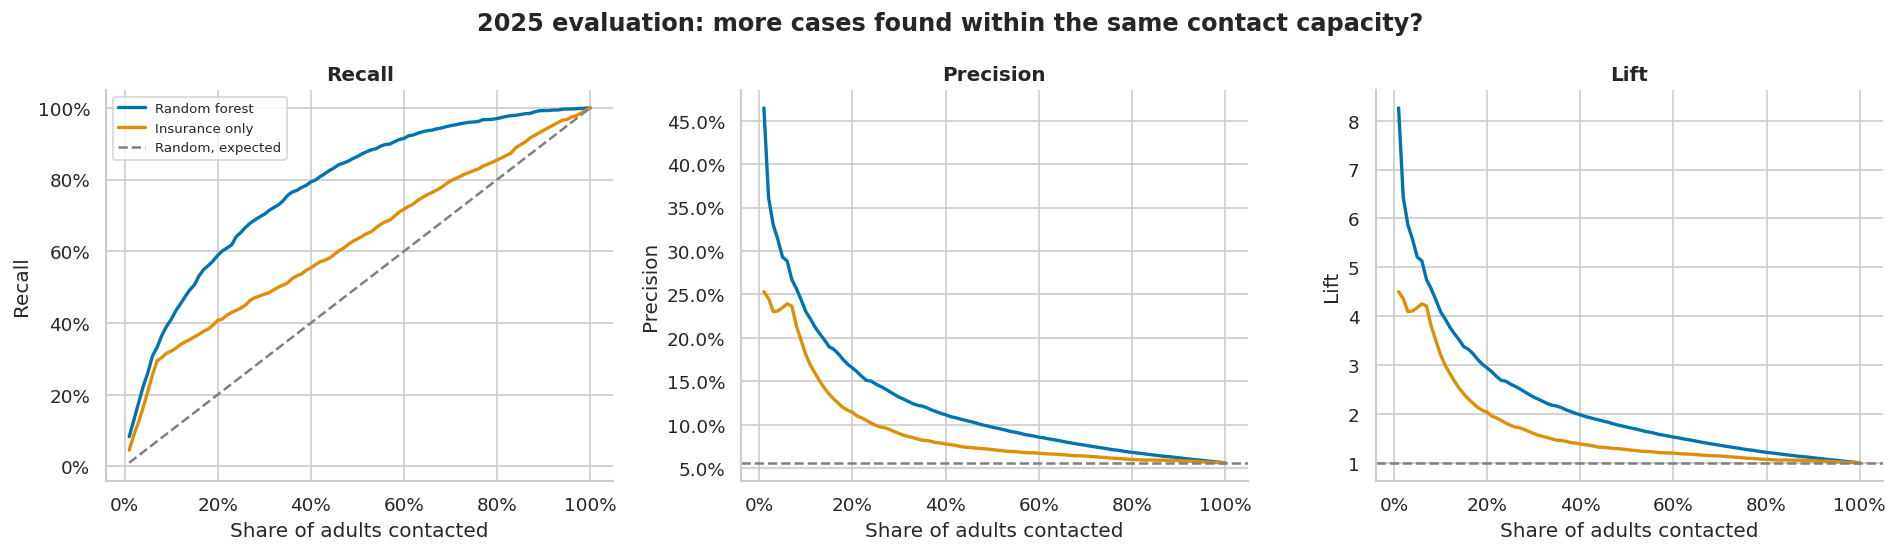

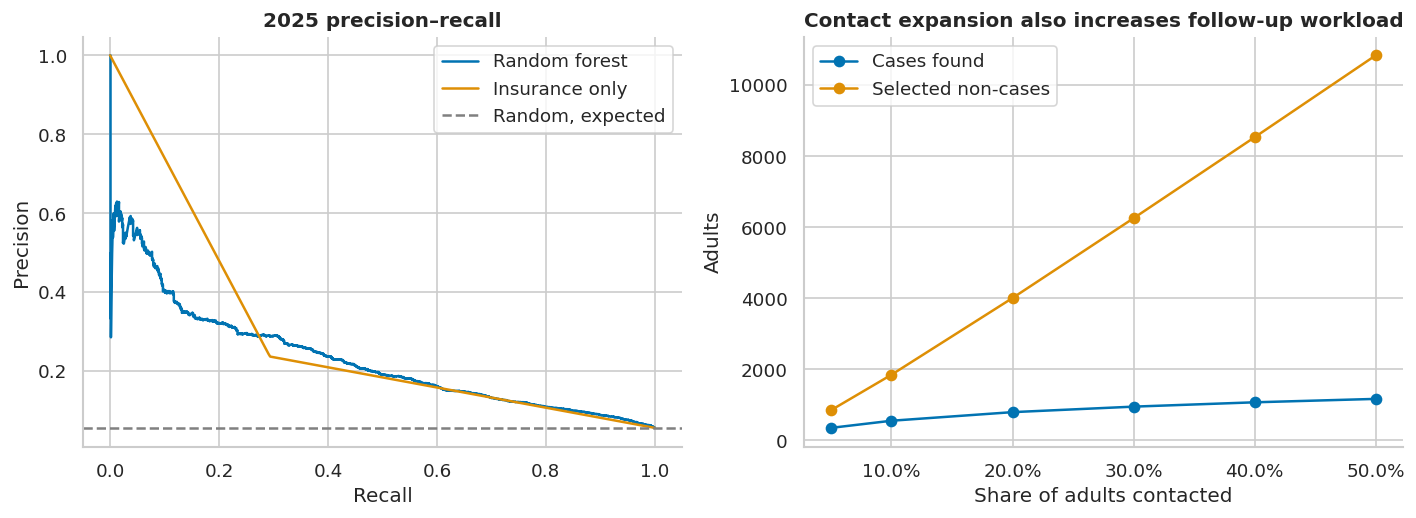

In [21]:
plot_capacity_curves(y_evaluation, {'Random forest': evaluation_scores, 'Insurance only': insurance_scores},
                     '2025 evaluation: more cases found within the same contact capacity?')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, scores in [('Random forest', evaluation_scores), ('Insurance only', insurance_scores)]:
    precision, recall, _ = precision_recall_curve(y_evaluation, scores)
    axes[0].plot(recall, precision, label=name)
axes[0].axhline(y_evaluation.mean(), color='grey', linestyle='--', label='Random, expected')
axes[0].set(title='2025 precision–recall', xlabel='Recall', ylabel='Precision')
axes[0].legend()
rf_capacity = evaluation_capacity_table.loc[evaluation_capacity_table['method'].eq('Random forest')]
axes[1].plot(rf_capacity['capacity'], rf_capacity['cases_found'], marker='o', label='Cases found')
axes[1].plot(rf_capacity['capacity'], rf_capacity['false_positives'], marker='o', label='Selected non-cases')
axes[1].set(title='Contact expansion also increases follow-up workload',
            xlabel='Share of adults contacted', ylabel='Adults')
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
plt.tight_layout(); plt.show()

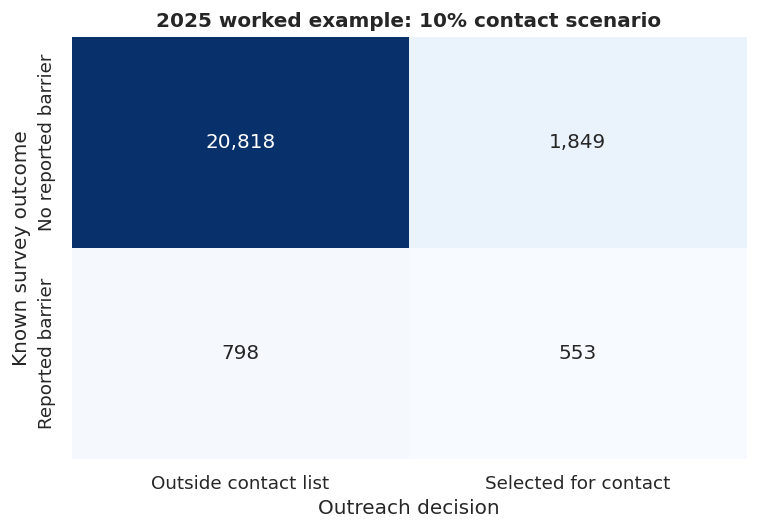

**Reading the worked example.** If capacity were **2,402 contacts** out of **24,018 eligible adults**, the random forest identifies **553 of 1,351 reported cases (40.9% recall)**. Insurance-only targeting identifies **434** at the same contact count; the forest therefore finds **119 additional cases**. Random selection would find about **135**, on average. Precision is **23.0%**, or about 23 actual cases per 100 contacts. Lift is **4.09**, meaning that concentration is 4.09 times the random-selection expectation, not 4.09 times the accuracy.

**What it misses.** At this capacity the procedure leaves **798 actual cases outside the list** and selects **1,849 people who did not report this outcome**. These selected non-cases may still have other support needs, but this dataset does not establish them. A lower capacity can improve yield per contact while missing more total cases; a higher capacity finds more cases but adds follow-up workload. A provider must make that resource decision.

In [22]:
example_q = 0.10  # Worked example only, not the provider's established budget.
example_rf = capacity_metrics(y_evaluation, evaluation_scores, example_q)
example_insurance = capacity_metrics(y_evaluation, insurance_scores, example_q)
example_selected = select_top_k(evaluation_scores, example_rf['contacts'])
example_matrix = confusion_matrix(y_evaluation, example_selected.astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.5, 4.6))
sns.heatmap(example_matrix, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Outside contact list', 'Selected for contact'],
            yticklabels=['No reported barrier', 'Reported barrier'])
ax.set(title='2025 worked example: 10% contact scenario', xlabel='Outreach decision', ylabel='Known survey outcome')
plt.tight_layout(); plt.show()

display(Markdown(f"**Reading the worked example.** If capacity were **{example_rf['contacts']:,} contacts** "
    f"out of **{len(evaluation):,} eligible adults**, the random forest identifies "
    f"**{example_rf['cases_found']:,} of {int(y_evaluation.sum()):,} reported cases ({example_rf['recall']:.1%} recall)**. "
    f"Insurance-only targeting identifies **{example_insurance['cases_found']:,}** at the same contact count; "
    f"the forest therefore finds **{example_rf['cases_found'] - example_insurance['cases_found']:,} additional cases**. "
    f"Random selection would find about **{example_rf['contacts'] * y_evaluation.mean():.0f}**, on average. "
    f"Precision is **{example_rf['precision']:.1%}**, or about {example_rf['precision'] * 100:.0f} actual cases "
    f"per 100 contacts. Lift is **{example_rf['lift']:.2f}**, meaning that concentration is "
    f"{example_rf['lift']:.2f} times the random-selection expectation, not {example_rf['lift']:.2f} times the accuracy."))
display(Markdown(f"**What it misses.** At this capacity the procedure leaves **{example_rf['missed_cases']:,} "
    f"actual cases outside the list** and selects **{example_rf['false_positives']:,} people who did not report "
    'this outcome**. These selected non-cases may still have other support needs, but this dataset does not '
    'establish them. A lower capacity can improve yield per contact while missing more total cases; '
    'a higher capacity finds more cases but adds follow-up workload. A provider must make that resource decision.'))

### Uncertainty around additional cases found
The next table uses a paired respondent bootstrap: both methods are evaluated on the same resampled adults, at the same number of contacts. The model is **not refitted**, and the outcomes are used only to quantify the already fixed comparison. The 10% scenario remains a worked example.

These intervals reflect respondent-sample variation under an independence assumption. They do **not** account fully for NHIS survey design, repeated earlier use of 2025, model-selection uncertainty, or transfer to a real provider. They should not be treated as national survey confidence intervals.

In [23]:
rng = np.random.default_rng(902)
bootstrap_rows = []
evaluation_y_array = np.asarray(y_evaluation)
for _ in range(300):
    idx = rng.integers(0, len(evaluation), size=len(evaluation))
    rf_m = capacity_metrics(evaluation_y_array[idx], evaluation_scores[idx], example_q)
    ins_m = capacity_metrics(evaluation_y_array[idx], insurance_scores[idx], example_q)
    bootstrap_rows.append({'extra_cases': rf_m['cases_found'] - ins_m['cases_found'],
                           'recall_difference': rf_m['recall'] - ins_m['recall']})
bootstrap_differences = pd.DataFrame(bootstrap_rows)
bootstrap_summary = bootstrap_differences.quantile([0.025, 0.50, 0.975]).T
bootstrap_summary.columns = ['lower_2.5%', 'median', 'upper_97.5%']
display(bootstrap_summary)

,lower_2.5%,median,upper_97.5%
extra_cases,101.0000,127.0000,148.5250
recall_difference,0.0743,0.0940,0.1105


### Does the priority population contain different profiles in 2025?
The following step assigns 2025 adults to the **already fixed** 2024 profile definitions. It does not create a new clustering solution. We describe the 20% planning scenario and show profile shares for 10%, 20% and 30% lists so one planning scope is not confused with a required budget.

Group outcome rates below are descriptive evaluation results, not information used to create groups or allocate additional contacts. The model and profiles remain unchanged after these results.

,profile,adults,share,median_age,uninsured,income_below_2x_poverty,fair_or_poor_health,no_usual_place,not_employed,reported_barrier_rate
0,Profile A,2825,0.5881,35.0000,0.3887,0.4053,0.2018,0.2885,0.1642,0.1710
1,Profile B,1979,0.4119,57.0000,0.2481,0.5225,0.5629,0.1344,0.4891,0.1577


capacity,0.1000,0.2000,0.3000
profile,,,
Profile A,0.6341,0.5881,0.5694
Profile B,0.3659,0.4119,0.4306


profile,possible_outreach_focus
Profile A,Ask about current cost barriers and explain available assistance pathways. Explore help connecting to a regular source of care.
Profile B,Review cost concerns alongside care navigation and existing coverage. Coordinate follow-up with the existing care team where appropriate.


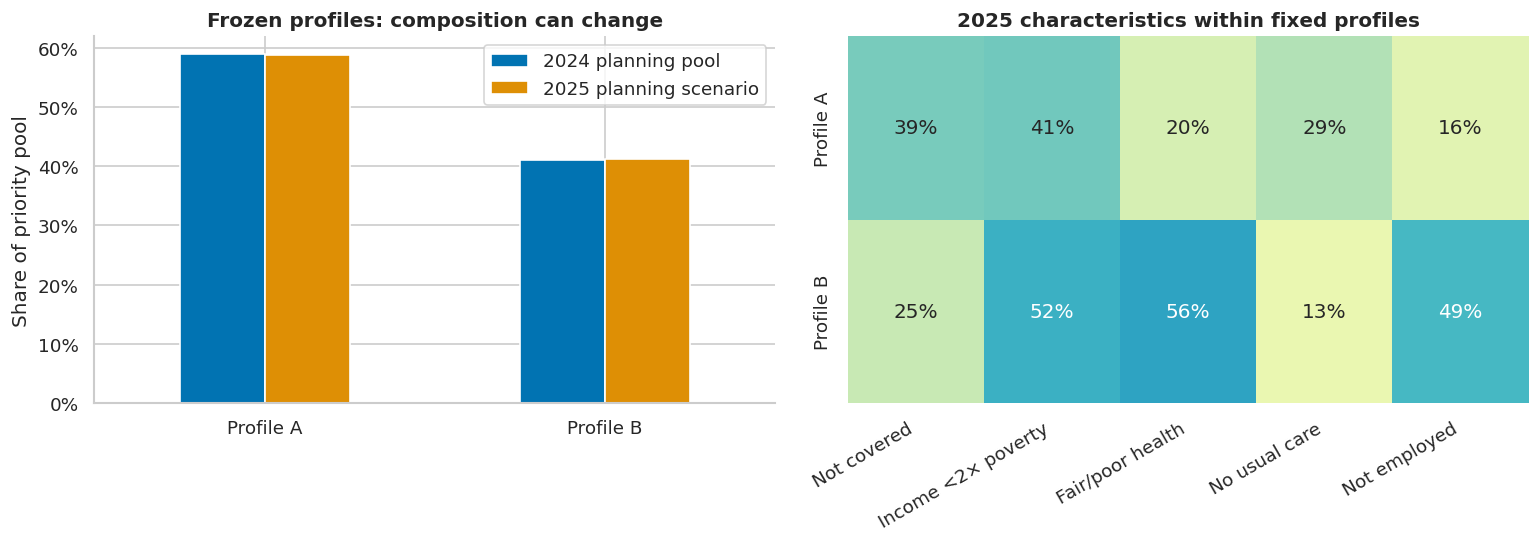

**Interpretation.** Read a profile as a combination, rather than a label that applies equally to every member. Differences between 2024 and 2025 shares show that the composition of a priority list can change even when the rules stay fixed. The classifier gives priority; the profiles suggest what to ask during follow-up. They do not demonstrate that tailored outreach reduces unmet need.

In [24]:
evaluation_profile_rows, profile_shares = [], []
for q in [0.10, 0.20, 0.30]:
    mask = select_top_k(evaluation_scores, int(np.ceil(q * len(evaluation))))
    selected_records = evaluation.loc[mask].copy()
    labels = profile_model.predict(profile_matrix(selected_records), categorical=PROFILE_CAT_INDEX)
    summary = profile_summary(selected_records, labels)
    profile_shares.append(summary[['profile', 'share']].assign(capacity=q))
    if np.isclose(q, PROFILE_FRACTION):
        evaluation_profile_summary = summary
        evaluation_profile_records = selected_records
        evaluation_profile_labels = labels
display(evaluation_profile_summary)
display(pd.concat(profile_shares).pivot(index='profile', columns='capacity', values='share'))
display(support_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
shares_plot = pd.DataFrame({
    '2024 planning pool': planning_profile_summary.set_index('profile')['share'],
    '2025 planning scenario': evaluation_profile_summary.set_index('profile')['share']}).fillna(0)
shares_plot.plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Frozen profiles: composition can change', ylabel='Share of priority pool', xlabel='')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
sns.heatmap(evaluation_profile_summary.set_index('profile')[profile_plot_columns],
            annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set(title='2025 characteristics within fixed profiles', xlabel='', ylabel='')
axes[1].set_xticklabels(['Not covered', 'Income <2× poverty', 'Fair/poor health',
                         'No usual care', 'Not employed'], rotation=30, ha='right')
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation.** Read a profile as a combination, rather than a label that applies '
                 'equally to every member. Differences between 2024 and 2025 shares show that the '
                 'composition of a priority list can change even when the rules stay fixed. The '
                 'classifier gives priority; the profiles suggest what to ask during follow-up. '
                 'They do not demonstrate that tailored outreach reduces unmet need.'))

## Part 9: Answering the Business Question
### What the provider can learn from the results
The following conclusion is generated from this run's measured results. It connects prediction quality to contacts and follow-up workload, rather than describing a model as good solely because of its accuracy.

In [25]:
rf20 = capacity_metrics(y_evaluation, evaluation_scores, 0.20)
ins20 = capacity_metrics(y_evaluation, insurance_scores, 0.20)
rf50 = capacity_metrics(y_evaluation, evaluation_scores, 0.50)
profile_lines = []
for _, r in evaluation_profile_summary.iterrows():
    profile_lines.append(
        f"- **{r['profile']}**: {r['share']:.1%} of the 20% planning list; median age {r['median_age']:.0f}, "
        f"{r['uninsured']:.0%} without coverage, {r['income_below_2x_poverty']:.0%} below twice the poverty threshold, "
        f"and {r['fair_or_poor_health']:.0%} reporting fair/poor health.")
display(Markdown(
    f"**1. Improve allocation.** The forest provides useful ranking information relative to the simple baselines. "
    f"In the illustrative 10% scenario, it finds **{example_rf['cases_found']:,} cases**, versus "
    f"**{example_insurance['cases_found']:,} with insurance-only targeting**, using the same "
    f"**{example_rf['contacts']:,} contacts**. At 20% capacity, it finds **{rf20['cases_found']:,} cases "
    f"({rf20['recall']:.1%} recall)**, compared with **{ins20['cases_found']:,}** for insurance-only targeting. "
    'The extra characteristics therefore add measured information beyond coverage alone. '
    'This does not establish that random forest is superior to every benchmark at every capacity.\n\n'
    f"**2. Understand the priority population.** The fixed descriptive analysis produces **{chosen_k} profiles**. "
    'In the supplied 2025 planning scenario:\n\n' + '\n'.join(profile_lines) + '\n\n'
    '**3. Translate the findings into a decision.** The provider should first state how many people staff '
    'can contact in a period, rank its eligible patients, and use the corresponding part of the capacity '
    'curve. Follow-up confirms whether a current barrier exists and which assistance pathway is relevant. '
    'Profiles can guide that conversation, but should not determine eligibility or exclude people from '
    'other routes to support. No unique optimal capacity or financial return can be calculated without '
    'staffing, contact-cost, reachability and benefit information.\n\n'
    f"**4. Recognise the limitations.** The 10% scenario still misses **{example_rf['missed_cases']:,} cases**, "
    f"and only **{example_rf['precision']:.1%}** of selected adults report this particular outcome. "
    'A ranked list supports scarce-resource decisions; it does not identify everybody who needs help. '
    'Higher recall achieved by making a longer list also consumes more resources. The data contain '
    'survey respondents, not a contactable clinic roster, and the target describes the previous 12 months. '
    'Patient-specific validation and an outreach pilot are needed to establish operational value.'
))

**1. Improve allocation.** The forest provides useful ranking information relative to the simple baselines. In the illustrative 10% scenario, it finds **553 cases**, versus **434 with insurance-only targeting**, using the same **2,402 contacts**. At 20% capacity, it finds **795 cases (58.8% recall)**, compared with **550** for insurance-only targeting. The extra characteristics therefore add measured information beyond coverage alone. This does not establish that random forest is superior to every benchmark at every capacity.

**2. Understand the priority population.** The fixed descriptive analysis produces **2 profiles**. In the supplied 2025 planning scenario:

- **Profile A**: 58.8% of the 20% planning list; median age 35, 39% without coverage, 41% below twice the poverty threshold, and 20% reporting fair/poor health.
- **Profile B**: 41.2% of the 20% planning list; median age 57, 25% without coverage, 52% below twice the poverty threshold, and 56% reporting fair/poor health.

**3. Translate the findings into a decision.** The provider should first state how many people staff can contact in a period, rank its eligible patients, and use the corresponding part of the capacity curve. Follow-up confirms whether a current barrier exists and which assistance pathway is relevant. Profiles can guide that conversation, but should not determine eligibility or exclude people from other routes to support. No unique optimal capacity or financial return can be calculated without staffing, contact-cost, reachability and benefit information.

**4. Recognise the limitations.** The 10% scenario still misses **798 cases**, and only **23.0%** of selected adults report this particular outcome. A ranked list supports scarce-resource decisions; it does not identify everybody who needs help. Higher recall achieved by making a longer list also consumes more resources. The data contain survey respondents, not a contactable clinic roster, and the target describes the previous 12 months. Patient-specific validation and an outreach pilot are needed to establish operational value.

### What has and has not been demonstrated
The measured improvement is **more reported cases identified per fixed number of simulated contacts**. It is not evidence that outreach causes better access, that financial assistance reduces costs by a particular amount, or that the scores predict the same people's future outcomes.

Further limitations include self-report and non-response, a narrow outcome that excludes dental care, broad predictors that omit plan details and actual out-of-pocket costs, possible changes between years, and differences between national survey respondents and a provider's patients. Unweighted model development aligns with this simulated contact list; national prevalence summaries require survey weights, and formal national uncertainty would require the full survey design. A low score does not establish that somebody has no support need.

Before implementation, the provider would need to confirm that the inputs can be collected consistently **before the support decision**, validate on its own later patient records, set a real contact capacity, check who is systematically missed, and measure the results of an outreach pilot. A provider can also retain self-referral and staff referrals for people outside the ranked list. These actions address practical transfer and support access; they are not claims already established by the notebook.

**Project-level conclusion:** Random forest is a reasonable, business-aligned prioritisation candidate when used with same-capacity evaluation and transparent baselines. Its small differences from other multivariate models do not justify a universal winner claim. The profiles add a separate descriptive view of the priority population, and both parts remain a proof of concept requiring provider-specific validation.

## Appendix
### A. Audit of data separation and frozen choices
These checks document that the executed procedure used the declared years, excluded answer-revealing fields, and did not fit anything after opening 2025. They complement the code review; no assertion can undo earlier project-level examination of this evaluation year.

In [26]:
state_digest_after = hashlib.sha256(pickle.dumps((final_model, final_insurance,
    final_constant, profile_age_imputer, profile_age_scaler, profile_model))).hexdigest()
audit = {
    'initial_training_2023_only': set(initial_train['YEAR']) == {2023},
    'validation_2024_only': set(validation['YEAR']) == {2024},
    'final_training_2023_2024_only': set(development['YEAR']) == {2023, 2024},
    'evaluation_2025_only': set(evaluation['YEAR']) == {2025},
    'no_development_evaluation_person_overlap': set(development['NHISPID']).isdisjoint(evaluation['NHISPID']),
    'predictors_exclude_target_year_ids_and_survey_design': not bool(set(PREDICTORS).intersection(EXCLUDED)),
    'profiles_exclude_target_scores_year_ids_and_weights': not bool(set(PROFILE_COLUMNS).intersection(EXCLUDED + ['score'])),
    'all_logged_fits_before_evaluation': len(FIT_LOG) == FITS_BEFORE_TEST,
    'all_logged_fit_years_are_development': all(set(r['years']).issubset({2023, 2024}) for r in FIT_LOG),
    'settings_unchanged_after_evaluation': freeze_digest(frozen_choices) == CHOICE_DIGEST,
    'fitted_parameters_unchanged_after_evaluation': state_digest_after == fitted_state_digest,
    'same_contacts_for_every_method_at_each_capacity': bool(
        evaluation_capacity_table.groupby('capacity')['contacts'].nunique().eq(1).all()),
    'classification_counts_reconcile': bool((evaluation_capacity_table['cases_found'] +
        evaluation_capacity_table['missed_cases']).eq(int(y_evaluation.sum())).all()),
    'false_positive_counts_reconcile': bool((evaluation_capacity_table['cases_found'] +
        evaluation_capacity_table['false_positives']).eq(evaluation_capacity_table['contacts']).all()),
}
assert all(audit.values()), audit
display(pd.Series(audit, name='passed').to_frame())
print('All separation, frozen-state and arithmetic checks passed.')

All separation, frozen-state and arithmetic checks passed.


,passed
initial_training_2023_only,True
validation_2024_only,True
final_training_2023_2024_only,True
evaluation_2025_only,True
no_development_evaluation_person_overlap,True
predictors_exclude_target_year_ids_and_survey_design,True
profiles_exclude_target_scores_year_ids_and_weights,True
all_logged_fits_before_evaluation,True
all_logged_fit_years_are_development,True
settings_unchanged_after_evaluation,True


### B. Survey-weighted sensitivity and missing inputs in later data
These weighted metrics use the **same selected respondents** at each scenario. Weighted precision describes the represented population within that list; weighted recall describes the share of represented positive cases captured. Selecting 10% of respondents does not necessarily select 10% of the population weight. These are secondary summaries, not the primary respondent-workload objective or survey-design-adjusted estimates of uncertainty.

In [27]:
weighted_rows = []
w = evaluation['SAMPWEIGHT'].to_numpy()
y = y_evaluation.to_numpy()
for name, scores in [('Random forest', evaluation_scores), ('Insurance only', insurance_scores)]:
    for q in CAPACITIES:
        selected = select_top_k(scores, int(np.ceil(q * len(y))))
        weighted_tp = np.sum(w * y * selected)
        precision = weighted_tp / w[selected].sum()
        weighted_rows.append({'method': name, 'capacity': q,
                              'weighted_precision': precision,
                              'weighted_recall': weighted_tp / np.sum(w * y),
                              'weighted_lift': precision / np.average(y, weights=w),
                              'population_weight_selected': w[selected].sum() / w.sum()})
weighted_evaluation = pd.DataFrame(weighted_rows)
display(weighted_evaluation)
missing_shift = pd.DataFrame({'development_missing_%': development[PREDICTORS].isna().mean() * 100,
                              'evaluation_missing_%': evaluation[PREDICTORS].isna().mean() * 100})
display(missing_shift)
unseen_categories = []
for col in CATEGORICAL:
    new = set(evaluation[col].dropna().unique()) - set(development[col].dropna().unique())
    unseen_categories.append({'variable': col, 'unseen_evaluation_categories': sorted(new)})
display(pd.DataFrame(unseen_categories))
display(subgroup_report(evaluation, evaluation_scores, 0.10))

,method,capacity,weighted_precision,weighted_recall,weighted_lift,population_weight_selected
0,Random forest,0.0500,0.2784,0.2943,4.5807,0.0642
1,Random forest,0.1000,0.2226,0.4577,3.6627,0.1250
2,Random forest,0.2000,0.1640,0.6360,2.6987,0.2357
3,Random forest,0.3000,0.1298,0.7405,2.1359,0.3467
4,Random forest,0.4000,0.1099,0.8304,1.8077,0.4594
5,Random forest,0.5000,0.0963,0.8930,1.5838,0.5639
6,Insurance only,0.0500,0.2179,0.2381,3.5858,0.0664
7,Insurance only,0.1000,0.1808,0.3654,2.9752,0.1228
8,Insurance only,0.2000,0.1237,0.4502,2.0346,0.2213
9,Insurance only,0.3000,0.0994,0.5161,1.6354,0.3156


,development_missing_%,evaluation_missing_%
REGION,0.0000,0.0000
AGE,0.1769,0.2456
SEX,0.0178,0.0958
HISPRACE,0.0000,0.0000
EDUC,0.4559,0.3414
EMPSTAT,3.2160,2.4149
POVERTY,0.0000,0.0000
HEALTH,0.0552,0.0291
USUALPL,0.0746,0.0458
HINOTCOVE,0.2612,0.2581


,variable,unseen_evaluation_categories
0,REGION,[]
1,SEX,[]
2,HISPRACE,[]
3,EDUC,[]
4,EMPSTAT,[]
5,POVERTY,[]
6,HEALTH,[]
7,USUALPL,[]
8,HINOTCOVE,[]


,variable,group,adults,actual_cases,contacts,cases_found,selection_rate,recall,precision
0,HINOTCOVE,Covered,22342,954,1007,181,0.0451,0.1897,0.1797
1,HINOTCOVE,Not covered,1614,393,1394,372,0.8637,0.9466,0.2669
2,HINOTCOVE,Missing,62,4,1,0,0.0161,0.0000,0.0000
3,SEX,Male,11120,548,975,212,0.0877,0.3869,0.2174
4,SEX,Female,12875,801,1424,339,0.1106,0.4232,0.2381
5,SEX,Missing,23,2,3,2,0.1304,1.0000,0.6667
6,HISPRACE,Hispanic,3377,269,657,145,0.1946,0.5390,0.2207
7,HISPRACE,Non-Hispanic White,15910,794,1309,305,0.0823,0.3841,0.2330
8,HISPRACE,Non-Hispanic Black,2677,197,306,74,0.1143,0.3756,0.2418
9,HISPRACE,Non-Hispanic Asian,1440,47,40,11,0.0278,0.2340,0.2750


### C. Key terms and reproducibility

| Term | Meaning in this project |
|---|---|
| Feature / predictor | An input such as age or coverage status |
| Target / label | The known Yes/No answer to the affordability question |
| Training | Learning patterns from labelled examples |
| Hyperparameter | A setting chosen before fitting, such as minimum leaf size |
| Validation | Development data used to compare procedures |
| Pipeline | A repeatable sequence that learns preprocessing and the model together |
| Refitting | Training the chosen procedure again on all available development years |
| Out-of-time evaluation | Checking the fixed procedure on respondents from a later year |
| Ranking versus probability | Score order can be useful even when exact risk estimates need calibration |
| Cluster / profile | A descriptive group with similar selected characteristics; not a verified support need |

The fixed random seed makes model fitting, tie handling and clustering repeatable under the recorded software. Exact results may vary across library versions. Scikit-learn should support `OneHotEncoder(sparse_output=...)` and `make_scorer(response_method=...)` (use scikit-learn 1.4 or newer). Use pandas 2.2 or newer for the grouped chart calculation. The small grids do not prove that the best possible forest has been found.

**Source integration.** The original `code.ipynb` in `kellykwok20-del/DBA3803-Grp12` supplied the project objective, variable set, cleaning rules and weighted EDA approach. Its initial early read of the test file was moved into the final evaluation section. Missing employment code 900 is also treated as non-response for completeness; it is absent from the supplied development sample. The wage example supplied the analytical flow, not the classification objective or the outcomes reported here.

### D. References
- [IPUMS NHIS: YBARCARE definition, universe, survey wording and weights](https://nhis.ipums.org/nhis-action/variables/YBARCARE).
- [IPUMS NHIS: HINOTCOVE coverage definition and codes](https://nhis.ipums.org/nhis-action/variables/HINOTCOVE).
- [IPUMS NHIS: poverty categories](https://nhis.ipums.org/nhis-action/variables/POVERTY), [education](https://nhis.ipums.org/nhis-action/variables/EDUC), [employment](https://nhis.ipums.org/nhis-action/variables/EMPSTAT), and [age](https://nhis.ipums.org/nhis-action/variables/AGE).
- [KFF (2023), Survey of Consumer Experiences with Health Insurance](https://www.kff.org/affordable-care-act/kff-survey-of-consumer-experiences-with-health-insurance/). Background context; not the model target.
- Scikit-learn: [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [nicodv/kmodes: k-prototypes implementation for mixed numerical and categorical data](https://github.com/nicodv/kmodes).
- Course-supplied `wage_regression.html` and the [project repository](https://github.com/kellykwok20-del/DBA3803-Grp12).

External sources support variable meaning and methods. All numerical model results and profiles are calculated from the supplied project files.